Starting Phase 1: Dataset Inspection...

------------------------------
DATASET STATISTICS (Table 1 Data)
------------------------------
             Class  Number of Images Percentage
       Anthracnose               773     23.04%
             Dried               271      8.08%
           Healthy               831     24.77%
Insect_Infestation               441     13.14%
        Senescence               510     15.20%
       Sooty_Mould               529     15.77%

Total Valid Images: 3355
Corrupted Files Found: 0
Exact Duplicates Found: 1

Image Dimensions:
  Min: 512x512
  Max: 4000x3000
  Mean: 515x514

Saved Figure 1 to 'figure1_class_distribution.png'
Saved Figure 2 to 'figure2_sample_grid.png'


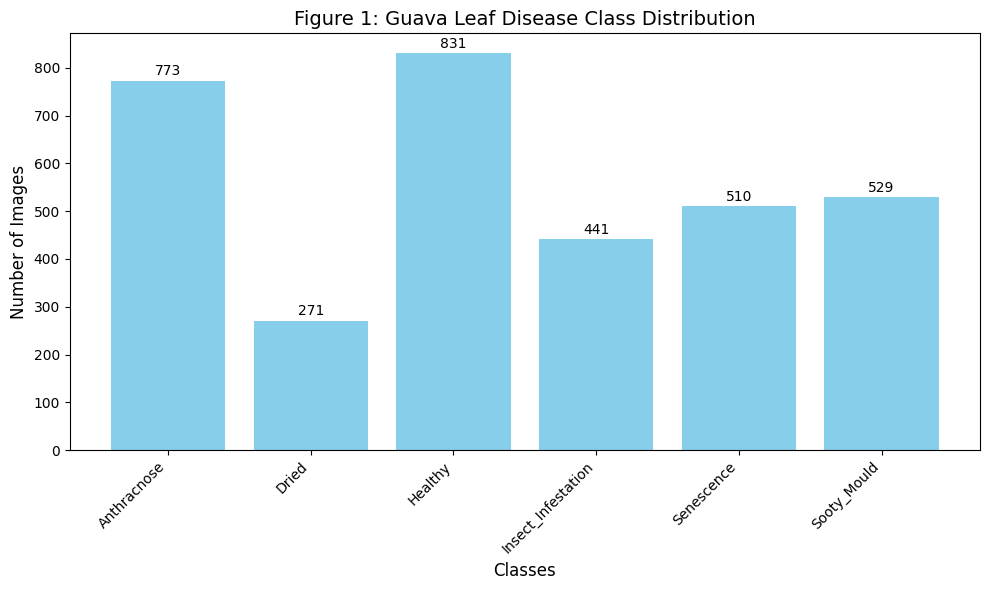

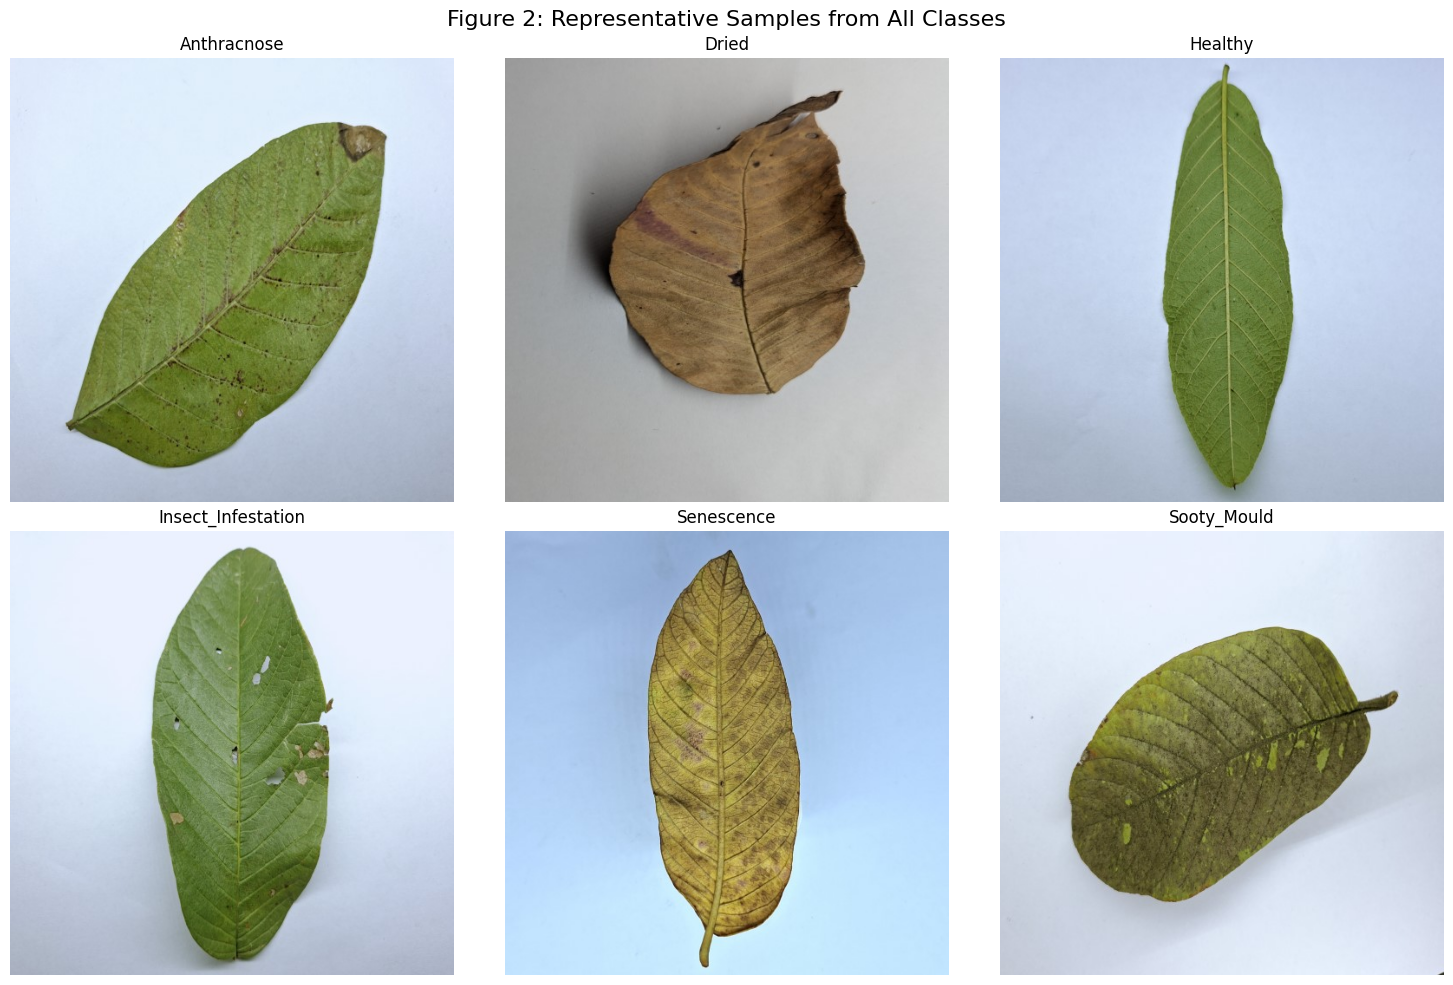

In [1]:
import os
import hashlib
from collections import Counter
from PIL import Image
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Configuration
DATA_DIR = "/kaggle/input/datasets/zahedulislamtapu/guava-leaf-disease-mendeley/Guava_Leaf" # UPDATE THIS to your dataset path
EXPECTED_CLASSES = ["Anthracnose", "Dried", "Healthy", "Insect_Infestation", "Senescence", "Sooty_Mould"]

def get_image_hash(filepath):
    """Returns MD5 hash of a file for exact duplicate detection."""
    with open(filepath, "rb") as f:
        file_hash = hashlib.md5()
        chunk = f.read(8192)
        while chunk:
            file_hash.update(chunk)
            chunk = f.read(8192)
    return file_hash.hexdigest()

def analyze_dataset():
    print("Starting Phase 1: Dataset Inspection...\n")
    
    class_counts = {}
    corrupted_files = []
    image_dimensions = []
    file_hashes = {}
    duplicates = []
    valid_image_paths = {cls: [] for cls in EXPECTED_CLASSES}

    # 1. Traverse Directories
    for cls in EXPECTED_CLASSES:
        cls_dir = os.path.join(DATA_DIR, cls)
        if not os.path.exists(cls_dir):
            print(f"WARNING: Directory for class '{cls}' not found!")
            continue
            
        images = [f for f in os.listdir(cls_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        class_counts[cls] = 0
        
        for img_name in images:
            img_path = os.path.join(cls_dir, img_name)
            
            # 2. Check for corruption & dimensions
            try:
                with Image.open(img_path) as img:
                    img.verify() # Verify file integrity
                # Reopen to get details (verify() closes the file)
                with Image.open(img_path) as img:
                    width, height = img.size
                    mode = img.mode
                    if mode != 'RGB':
                        print(f"Non-RGB image found: {img_path} (Mode: {mode})")
                    image_dimensions.append((width, height))
                    valid_image_paths[cls].append(img_path)
                    class_counts[cls] += 1
            except Exception as e:
                corrupted_files.append((img_path, str(e)))
                continue
                
            # 3. Check for duplicates
            img_hash = get_image_hash(img_path)
            if img_hash in file_hashes:
                duplicates.append((img_path, file_hashes[img_hash]))
            else:
                file_hashes[img_hash] = img_path

    # 4. Compile Statistics
    total_images = sum(class_counts.values())
    print("-" * 30)
    print("DATASET STATISTICS (Table 1 Data)")
    print("-" * 30)
    df_stats = pd.DataFrame([
        {"Class": cls, "Number of Images": count, "Percentage": f"{(count/total_images)*100:.2f}%"}
        for cls, count in class_counts.items()
    ])
    print(df_stats.to_string(index=False))
    print(f"\nTotal Valid Images: {total_images}")
    print(f"Corrupted Files Found: {len(corrupted_files)}")
    print(f"Exact Duplicates Found: {len(duplicates)}")
    
    if image_dimensions:
        widths, heights = zip(*image_dimensions)
        print(f"\nImage Dimensions:")
        print(f"  Min: {min(widths)}x{min(heights)}")
        print(f"  Max: {max(widths)}x{max(heights)}")
        print(f"  Mean: {int(np.mean(widths))}x{int(np.mean(heights))}")

    return class_counts, valid_image_paths

def plot_distribution(class_counts):
    """Generates Figure 1: Class Distribution."""
    plt.figure(figsize=(10, 6))
    bars = plt.bar(class_counts.keys(), class_counts.values(), color='skyblue')
    plt.title('Figure 1: Guava Leaf Disease Class Distribution', fontsize=14)
    plt.xlabel('Classes', fontsize=12)
    plt.ylabel('Number of Images', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    
    # Add value labels
    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, yval + 5, int(yval), ha='center', va='bottom')
        
    plt.tight_layout()
    plt.savefig('figure1_class_distribution.png', dpi=300)
    print("\nSaved Figure 1 to 'figure1_class_distribution.png'")

def plot_sample_grid(valid_image_paths):
    """Generates Figure 2: Representative image grid."""
    plt.figure(figsize=(15, 10))
    plt.suptitle('Figure 2: Representative Samples from All Classes', fontsize=16)
    
    for i, cls in enumerate(EXPECTED_CLASSES):
        if valid_image_paths.get(cls):
            img_path = valid_image_paths[cls][0] # Grab the first valid image
            img = Image.open(img_path)
            plt.subplot(2, 3, i + 1)
            plt.imshow(img)
            plt.title(cls)
            plt.axis('off')
            
    plt.tight_layout()
    plt.savefig('figure2_sample_grid.png', dpi=300)
    print("Saved Figure 2 to 'figure2_sample_grid.png'")

if __name__ == "__main__":
    counts, valid_paths = analyze_dataset()
    plot_distribution(counts)
    plot_sample_grid(valid_paths)

In [2]:
import os
import hashlib
import pandas as pd
from sklearn.model_selection import train_test_split

# Configuration
DATA_DIR = "/kaggle/input/datasets/zahedulislamtapu/guava-leaf-disease-mendeley/Guava_Leaf" # Update if your Kaggle path is different
EXPECTED_CLASSES = ["Anthracnose", "Dried", "Healthy", "Insect_Infestation", "Senescence", "Sooty_Mould"]
SEED = 42

def get_image_hash(filepath):
    with open(filepath, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

def create_stratified_split():
    print("Starting Phase 2: Dataset Splitting...\n")
    
    data = []
    seen_hashes = set()
    duplicate_count = 0

    # 1. Gather all file paths and labels, filtering out duplicates
    for cls in EXPECTED_CLASSES:
        cls_dir = os.path.join(DATA_DIR, cls)
        if not os.path.exists(cls_dir):
            continue
            
        images = [f for f in os.listdir(cls_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        for img_name in images:
            img_path = os.path.join(cls_dir, img_name)
            
            img_hash = get_image_hash(img_path)
            if img_hash in seen_hashes:
                duplicate_count += 1
                continue # Skip the duplicate
            
            seen_hashes.add(img_hash)
            # Store a relative path from the dataset root for portability
            relative_path = os.path.join(cls, img_name)
            data.append({"filepath": relative_path, "class": cls})

    df = pd.DataFrame(data)
    print(f"Total unique images ready for splitting: {len(df)} (Removed {duplicate_count} duplicate)")

    # 2. Perform Stratified Split (70% Train, 30% Temp)
    train_df, temp_df = train_test_split(
        df, test_size=0.30, random_state=SEED, stratify=df['class']
    )

    # 3. Split Temp into 15% Validation and 15% Test
    # (Since Temp is 30% of total, halving it gives 15% and 15%)
    val_df, test_df = train_test_split(
        temp_df, test_size=0.50, random_state=SEED, stratify=temp_df['class']
    )

    # 4. Label the splits and combine
    train_df = train_df.copy()
    train_df['split'] = 'train'
    
    val_df = val_df.copy()
    val_df['split'] = 'val'
    
    test_df = test_df.copy()
    test_df['split'] = 'test'

    final_df = pd.concat([train_df, val_df, test_df], ignore_index=True)

    # 5. Save to CSV
    output_path = "/kaggle/working/dataset_split.csv"
    final_df.to_csv(output_path, index=False)
    print(f"\nSaved split mapping to: {output_path}")

    # 6. Verify and display the split distribution
    print("\n--- Split Verification ---")
    summary = final_df.groupby(['split', 'class']).size().unstack(fill_value=0)
    summary['Total'] = summary.sum(axis=1)
    print(summary)
    
    return final_df

if __name__ == "__main__":
    create_stratified_split()

Starting Phase 2: Dataset Splitting...

Total unique images ready for splitting: 3354 (Removed 1 duplicate)

Saved split mapping to: /kaggle/working/dataset_split.csv

--- Split Verification ---
class  Anthracnose  Dried  Healthy  Insect_Infestation  Senescence  \
split                                                                
test           116     40      125                  66          77   
train          541    190      581                 309         357   
val            116     41      125                  66          76   

class  Sooty_Mould  Total  
split                      
test            80    504  
train          369   2347  
val             79    503  


In [3]:
import os
import pandas as pd
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Configuration
DATA_DIR = "/kaggle/input/datasets/zahedulislamtapu/guava-leaf-disease-mendeley/Guava_Leaf"
CSV_FILE = "/kaggle/working/dataset_split.csv"
BATCH_SIZE = 32
IMAGE_SIZE = 224

# 1. Define Transforms
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5), # Scientifically reasonable for leaves
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 2. Define the Custom Dataset
class GuavaLeafDataset(Dataset):
    def __init__(self, csv_file, root_dir, split, transform=None):
        """
        Args:
            csv_file (string): Path to the csv file with split mapping.
            root_dir (string): Directory with all the images.
            split (string): 'train', 'val', or 'test'.
            transform (callable, optional): Optional transform to be applied.
        """
        self.dataframe = pd.read_csv(csv_file)
        self.dataframe = self.dataframe[self.dataframe['split'] == split].reset_index(drop=True)
        self.root_dir = root_dir
        self.transform = transform
        
        # Create a class-to-index mapping
        self.classes = sorted(self.dataframe['class'].unique())
        self.class_to_idx = {cls_name: i for i, cls_name in enumerate(self.classes)}
        
    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()

        img_rel_path = self.dataframe.iloc[idx]['filepath']
        img_path = os.path.join(self.root_dir, img_rel_path)
        
        # Convert to RGB to ensure 3 channels
        image = Image.open(img_path).convert('RGB')
        
        label_name = self.dataframe.iloc[idx]['class']
        label = self.class_to_idx[label_name]

        if self.transform:
            image = self.transform(image)

        return image, label

# 3. Initialize Datasets and DataLoaders
print("Initializing PyTorch Datasets...")

train_dataset = GuavaLeafDataset(csv_file=CSV_FILE, root_dir=DATA_DIR, split='train', transform=train_transform)
val_dataset = GuavaLeafDataset(csv_file=CSV_FILE, root_dir=DATA_DIR, split='val', transform=val_test_transform)
test_dataset = GuavaLeafDataset(csv_file=CSV_FILE, root_dir=DATA_DIR, split='test', transform=val_test_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train Dataset size: {len(train_dataset)}")
print(f"Validation Dataset size: {len(val_dataset)}")
print(f"Test Dataset size: {len(test_dataset)}")
print(f"Classes mapping: {train_dataset.class_to_idx}")

# Fetch one batch to verify
images, labels = next(iter(train_loader))
print(f"\nBatch Image Tensor Shape: {images.shape} (Expected: {BATCH_SIZE}, 3, {IMAGE_SIZE}, {IMAGE_SIZE})")
print(f"Batch Label Tensor Shape: {labels.shape}")

Initializing PyTorch Datasets...
Train Dataset size: 2347
Validation Dataset size: 503
Test Dataset size: 504
Classes mapping: {'Anthracnose': 0, 'Dried': 1, 'Healthy': 2, 'Insect_Infestation': 3, 'Senescence': 4, 'Sooty_Mould': 5}

Batch Image Tensor Shape: torch.Size([32, 3, 224, 224]) (Expected: 32, 3, 224, 224)
Batch Label Tensor Shape: torch.Size([32])


In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.cuda.amp import autocast, GradScaler
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import numpy as np
import time
import copy
import matplotlib.pyplot as plt  # Added for plotting

# 1. Define the Baseline CNN Architecture
class BaselineCNN(nn.Module):
    def __init__(self, num_classes=6):
        super(BaselineCNN, self).__init__()
        
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )
        
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )
        
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)) # Global Average Pooling
        )
        
        self.classifier = nn.Sequential(
            nn.Dropout(p=0.5),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

# 2. Compute Class Weights for Imbalance
def compute_class_weights(dataset):
    class_counts = dataset.dataframe['class'].value_counts().sort_index().values
    total_samples = sum(class_counts)
    num_classes = len(class_counts)
    class_weights = total_samples / (num_classes * class_counts)
    return torch.tensor(class_weights, dtype=torch.float)

# 3. Training Loop with History Tracking
def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=7):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Training on device: {device}")
    model.to(device)
    
    scaler = GradScaler()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_macro_f1 = 0.0
    epochs_no_improve = 0
    
    # Dictionary to store metrics for plotting
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    
    for epoch in range(num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")
        print("-" * 15)
        
        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
                dataloader = train_loader
            else:
                model.eval()
                dataloader = val_loader
                
            running_loss = 0.0
            all_preds = []
            all_labels = []
            
            for inputs, labels in dataloader:
                inputs = inputs.to(device)
                labels = labels.to(device)
                
                optimizer.zero_grad()
                
                with torch.set_grad_enabled(phase == 'train'):
                    with autocast():
                        outputs = model(inputs)
                        loss = criterion(outputs, labels)
                        _, preds = torch.max(outputs, 1)
                        
                    if phase == 'train':
                        scaler.scale(loss).backward()
                        scaler.step(optimizer)
                        scaler.update()
                        
                running_loss += loss.item() * inputs.size(0)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())
                
            epoch_loss = running_loss / len(dataloader.dataset)
            epoch_acc = accuracy_score(all_labels, all_preds)
            precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro', zero_division=0)
            
            print(f"{phase.capitalize()} Loss: {epoch_loss:.4f} | Acc: {epoch_acc:.4f} | Macro-F1: {f1:.4f}")
            
            # Save metrics to history
            if phase == 'train':
                history['train_loss'].append(epoch_loss)
                history['train_acc'].append(epoch_acc)
                scheduler.step()
            else:
                history['val_loss'].append(epoch_loss)
                history['val_acc'].append(epoch_acc)
                
                if f1 > best_macro_f1:
                    best_macro_f1 = f1
                    best_model_wts = copy.deepcopy(model.state_dict())
                    epochs_no_improve = 0
                    print("  --> Best model updated!")
                else:
                    epochs_no_improve += 1
                    
        if epochs_no_improve >= patience:
            print(f"\nEarly stopping triggered after {epoch+1} epochs.")
            break
            
    print(f"\nTraining complete. Best Val Macro-F1: {best_macro_f1:.4f}")
    model.load_state_dict(best_model_wts)
    return model, history

# 4. Plotting Function (Publication Quality)
def plot_training_curves(history, save_dir='/kaggle/working/'):
    epochs = range(1, len(history['train_acc']) + 1)
    
    # Plot Accuracy
    plt.figure(figsize=(8, 6))
    plt.plot(epochs, history['train_acc'], 'b-', label='Training Accuracy', linewidth=2)
    plt.plot(epochs, history['val_acc'], 'r-', label='Validation Accuracy', linewidth=2)
    plt.title('Baseline CNN: Accuracy over Epochs', fontsize=14)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Accuracy', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig(f'{save_dir}baseline_accuracy_curve.png', dpi=300)
    plt.close()
    
    # Plot Loss
    plt.figure(figsize=(8, 6))
    plt.plot(epochs, history['train_loss'], 'b-', label='Training Loss', linewidth=2)
    plt.plot(epochs, history['val_loss'], 'r-', label='Validation Loss', linewidth=2)
    plt.title('Baseline CNN: Loss over Epochs', fontsize=14)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig(f'{save_dir}baseline_loss_curve.png', dpi=300)
    plt.close()
    
    print(f"Saved accuracy and loss curves to {save_dir}")

# 5. Execution
if __name__ == "__main__":
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    baseline_model = BaselineCNN(num_classes=6)
    
    # Setup Loss with Class Weights
    weights = compute_class_weights(train_dataset).to(device)
    criterion = nn.CrossEntropyLoss(weight=weights)
    print(f"Computed Class Weights: {weights.cpu().numpy()}")
    
    # Setup Optimizer & Scheduler
    optimizer = optim.AdamW(baseline_model.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)
    
    # Start Training
    best_baseline, training_history = train_model(
        baseline_model, 
        train_loader, 
        val_loader, 
        criterion, 
        optimizer, 
        scheduler, 
        num_epochs=40, 
        patience=7
    )
    
    # Save Model
    torch.save(best_baseline.state_dict(), '/kaggle/working/baseline_cnn_weights.pth')
    print("Saved baseline model to /kaggle/working/baseline_cnn_weights.pth")
    
    # Generate Plots
    plot_training_curves(training_history)

Computed Class Weights: [0.72304374 2.0587718  0.6732645  1.2659116  1.0957049  1.0600723 ]
Training on device: cuda

Epoch 1/40
---------------


/tmp/ipykernel_22/4030074278.py:64: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Train Loss: 1.0296 | Acc: 0.5744 | Macro-F1: 0.5838


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Val Loss: 0.7362 | Acc: 0.7833 | Macro-F1: 0.8001
  --> Best model updated!

Epoch 2/40
---------------


...

Val Loss: 0.2159 | Acc: 0.9264 | Macro-F1: 0.9439
  --> Best model updated!

Epoch 40/40
---------------


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Train Loss: 0.2970 | Acc: 0.8637 | Macro-F1: 0.8843


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Val Loss: 0.2112 | Acc: 0.9085 | Macro-F1: 0.9296

Training complete. Best Val Macro-F1: 0.9439
Saved baseline model to /kaggle/working/baseline_cnn_weights.pth
Saved accuracy and loss curves to /kaggle/working/


--- 1. COMPUTATIONAL EFFICIENCY ---
Measuring Latency (Warming up GPU...)
Total Parameters: 94,470
Model Size:       0.37 MB
GFLOPs:           1.035
Latency (batch=1):0.87 ms ± 0.00 ms

--- 2. TEST SET EVALUATION ---
Test Accuracy:    0.8948
Test Macro-F1:    0.9132
Test Weighted-F1: 0.8954

Saved benchmark metrics to /kaggle/working/baseline_COMPUTATIONAL_EFFICIENCY.csv

Saved raw Confusion Matrix to /kaggle/working/baseline_confusion_matrix.png


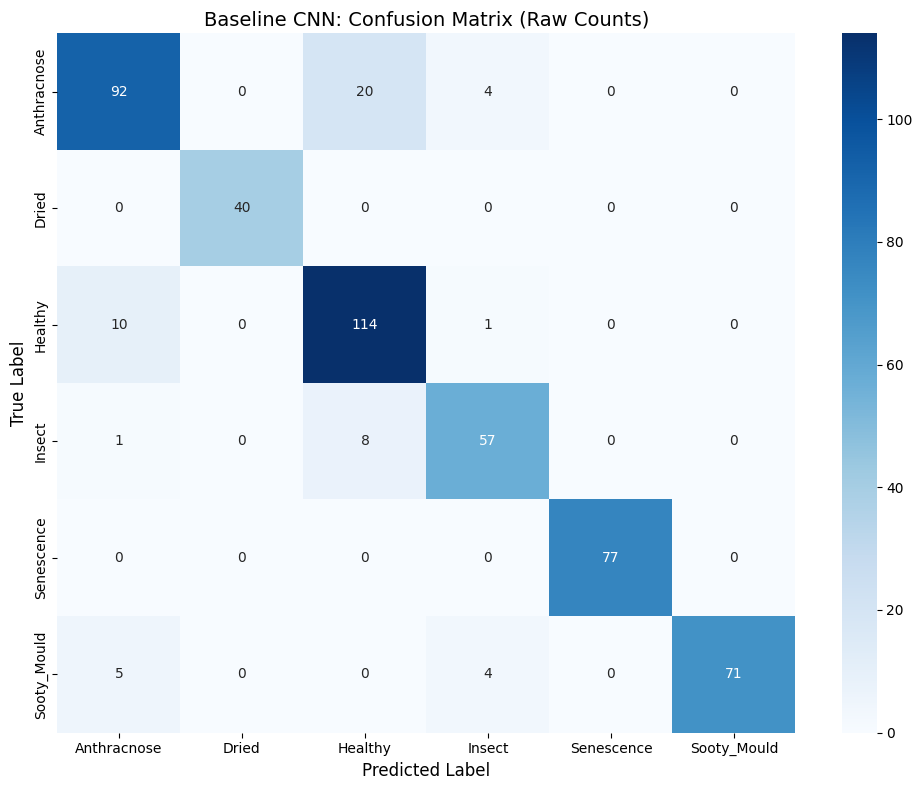

In [5]:
!pip install thop --quiet

import torch
import time
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from thop import profile

# 1. Initialize Model and Load Weights
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_path = '/kaggle/working/baseline_cnn_weights.pth'

# (Assuming BaselineCNN class is still in memory)
model = BaselineCNN(num_classes=6)
model.load_state_dict(torch.load(model_path))
model.to(device)
model.eval()

print("--- 1. COMPUTATIONAL EFFICIENCY ---")

# A. Parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

# B. Model Size (MB)
model_size_mb = os.path.getsize(model_path) / (1024 * 1024)

# C. FLOPs / MACs
dummy_input = torch.randn(1, 3, 224, 224).to(device)
macs, _ = profile(model, inputs=(dummy_input,), verbose=False)
flops_giga = (macs * 2) / 1e9 # Convert MACs to GFLOPs

# D. Inference Latency (GPU Warmup & Measurement)
print("Measuring Latency (Warming up GPU...)")
for _ in range(50):
    _ = model(dummy_input)

start_events = [torch.cuda.Event(enable_timing=True) for _ in range(100)]
end_events = [torch.cuda.Event(enable_timing=True) for _ in range(100)]

with torch.no_grad():
    for i in range(100):
        start_events[i].record()
        _ = model(dummy_input)
        end_events[i].record()

torch.cuda.synchronize()
times = [s.elapsed_time(e) for s, e in zip(start_events, end_events)]
mean_latency = np.mean(times)
std_latency = np.std(times)

print(f"Total Parameters: {total_params:,}")
print(f"Model Size:       {model_size_mb:.2f} MB")
print(f"GFLOPs:           {flops_giga:.3f}")
print(f"Latency (batch=1):{mean_latency:.2f} ms ± {std_latency:.2f} ms\n")

# 2. Test Set Evaluation
print("--- 2. TEST SET EVALUATION ---")
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)
        
        with torch.amp.autocast('cuda'):
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_acc = accuracy_score(all_labels, all_preds)
precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro', zero_division=0)
_, _, weighted_f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted', zero_division=0)

print(f"Test Accuracy:    {test_acc:.4f}")
print(f"Test Macro-F1:    {f1:.4f}")
print(f"Test Weighted-F1: {weighted_f1:.4f}\n")

# 3. Save Metrics to CSV
metrics_df = pd.DataFrame([{
    "Model": "BaselineCNN",
    "Parameters": total_params,
    "Size_MB": round(model_size_mb, 2),
    "GFLOPs": round(flops_giga, 3),
    "Latency_ms": round(mean_latency, 2),
    "Test_Accuracy": round(test_acc, 4),
    "Test_Macro_F1": round(f1, 4),
    "Test_Weighted_F1": round(weighted_f1, 4)
}])

csv_path = '/kaggle/working/baseline_COMPUTATIONAL_EFFICIENCY.csv'
metrics_df.to_csv(csv_path, index=False)
print(f"Saved benchmark metrics to {csv_path}\n")

# 4. Confusion Matrix (Raw Counts)
class_names = ['Anthracnose', 'Dried', 'Healthy', 'Insect', 'Senescence', 'Sooty_Mould']
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10, 8))
# Changed fmt to 'd' for integer counts, removed normalization
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.title('Baseline CNN: Confusion Matrix (Raw Counts)', fontsize=14)
plt.ylabel('True Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.tight_layout()
plt.savefig('/kaggle/working/baseline_confusion_matrix.png', dpi=300)
print("Saved raw Confusion Matrix to /kaggle/working/baseline_confusion_matrix.png")

In [6]:
import torch
import torch.nn as nn
from thop import profile
import pandas as pd

# 1. Squeeze-and-Excitation Attention Module
class SEBlock(nn.Module):
    def __init__(self, in_channels, reduction=4):
        super(SEBlock, self).__init__()
        self.se = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(in_channels, in_channels // reduction, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels // reduction, in_channels, 1, bias=False),
            nn.Hardsigmoid(inplace=True) # Hardsigmoid is more efficient than standard Sigmoid
        )

    def forward(self, x):
        return x * self.se(x)

# 2. Modular Custom Lightweight Block (Blueprint Section 11)
class CustomBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1, use_se=False, use_residual=False):
        super(CustomBlock, self).__init__()
        self.use_residual = use_residual and (in_channels == out_channels) and (stride == 1)
        
        # Depthwise Convolution (groups = in_channels)
        self.depthwise = nn.Sequential(
            nn.Conv2d(in_channels, in_channels, kernel_size=3, stride=stride, padding=1, groups=in_channels, bias=False),
            nn.BatchNorm2d(in_channels),
            nn.ReLU(inplace=True)
        )
        
        # Pointwise Convolution (1x1)
        self.pointwise = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
        
        self.se = SEBlock(out_channels) if use_se else nn.Identity()

    def forward(self, x):
        identity = x
        out = self.depthwise(x)
        out = self.pointwise(out)
        out = self.se(out)
        
        if self.use_residual:
            out = out + identity
            
        return out

# 3. The Custom Lightweight CNN Architecture
class CustomLightweightCNN(nn.Module):
    def __init__(self, num_classes=6, use_se=False, use_residual=False, channels=[32, 64, 128]):
        super(CustomLightweightCNN, self).__init__()
        
        # Initial Stem (Standard Conv)
        self.stem = nn.Sequential(
            nn.Conv2d(3, channels[0], kernel_size=3, stride=2, padding=1, bias=False), # Downsample immediately
            nn.BatchNorm2d(channels[0]),
            nn.ReLU(inplace=True)
        )
        
        # Custom Blocks
        self.block1 = CustomBlock(channels[0], channels[0], stride=1, use_se=use_se, use_residual=use_residual)
        
        self.block2 = CustomBlock(channels[0], channels[1], stride=2, use_se=use_se, use_residual=use_residual)
        self.block2_2 = CustomBlock(channels[1], channels[1], stride=1, use_se=use_se, use_residual=use_residual)
        
        self.block3 = CustomBlock(channels[1], channels[2], stride=2, use_se=use_se, use_residual=use_residual)
        self.block3_2 = CustomBlock(channels[2], channels[2], stride=1, use_se=use_se, use_residual=use_residual)
        
        # Classifier
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(p=0.4)
        self.fc = nn.Linear(channels[2], num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.block1(x)
        x = self.block2(x)
        x = self.block2_2(x)
        x = self.block3(x)
        x = self.block3_2(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        return x

# 4. Architecture Search Profiling (Blueprint Section 12)
if __name__ == "__main__":
    print("Running Architecture Search Profiling...\n")
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    dummy_input = torch.randn(1, 3, 224, 224).to(device)
    
    variants = {
        "CustomCNN-A (Base DW)": {"use_se": False, "use_residual": False},
        "CustomCNN-B (DW + SE)": {"use_se": True, "use_residual": False},
        "CustomCNN-C (DW + Res)": {"use_se": False, "use_residual": True},
        "CustomCNN-D (DW + SE + Res)": {"use_se": True, "use_residual": True}
    }
    
    results = []
    
    for name, config in variants.items():
        model = CustomLightweightCNN(use_se=config["use_se"], use_residual=config["use_residual"]).to(device)
        model.eval()
        
        total_params = sum(p.numel() for p in model.parameters())
        macs, _ = profile(model, inputs=(dummy_input,), verbose=False)
        flops_giga = (macs * 2) / 1e9
        
        results.append({
            "Variant": name,
            "Parameters": total_params,
            "GFLOPs": round(flops_giga, 4)
        })
        
    # Print the comparison table
    df_results = pd.DataFrame(results)
    print("-" * 50)
    print("ARCHITECTURE VARIANTS (Pre-Training Profiling)")
    print("-" * 50)
    print(df_results.to_string(index=False))
    
    print("\nBaseline Reference:")
    print("BaselineCNN: Parameters: ~94,470 | GFLOPs: ~1.035")

Running Architecture Search Profiling...

--------------------------------------------------
ARCHITECTURE VARIANTS (Pre-Training Profiling)
--------------------------------------------------
                    Variant  Parameters  GFLOPs
      CustomCNN-A (Base DW)       37798  0.1581
      CustomCNN-B (DW + SE)       58790  0.1601
     CustomCNN-C (DW + Res)       37798  0.1581
CustomCNN-D (DW + SE + Res)       58790  0.1601

Baseline Reference:
BaselineCNN: Parameters: ~94,470 | GFLOPs: ~1.035


--- Phase 7: Training Proposed CustomCNN-D ---
Training on device: cuda

Epoch 1/40
---------------


/tmp/ipykernel_22/4030074278.py:64: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Train Loss: 1.1723 | Acc: 0.5232 | Macro-F1: 0.5413


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Val Loss: 0.6665 | Acc: 0.7674 | Macro-F1: 0.8030
  --> Best model updated!

Epoch 2/40
---------------


...

Val Loss: 0.0207 | Acc: 0.9920 | Macro-F1: 0.9933

Epoch 34/40
---------------


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Train Loss: 0.0608 | Acc: 0.9744 | Macro-F1: 0.9789


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Val Loss: 0.0236 | Acc: 0.9901 | Macro-F1: 0.9915

Early stopping triggered after 34 epochs.

Training complete. Best Val Macro-F1: 0.9968
Saved Proposed Model weights to /kaggle/working/custom_cnn_d_weights.pth


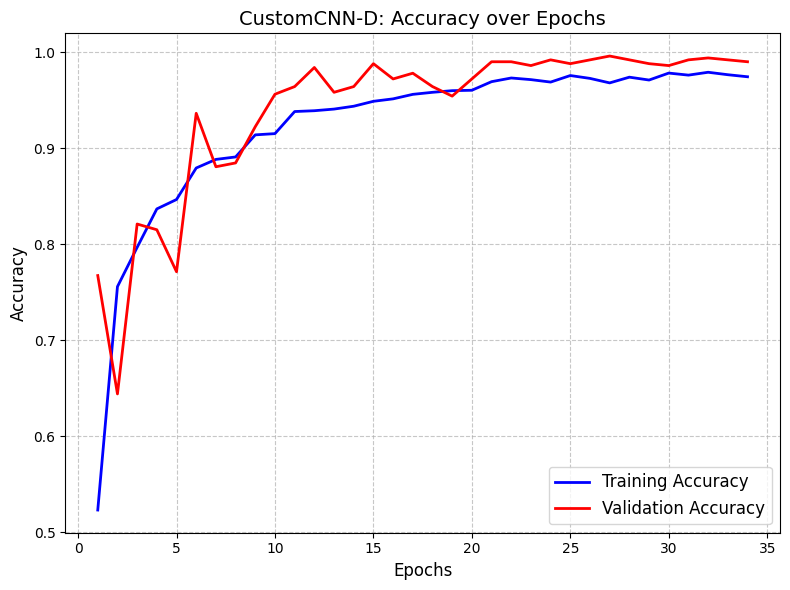

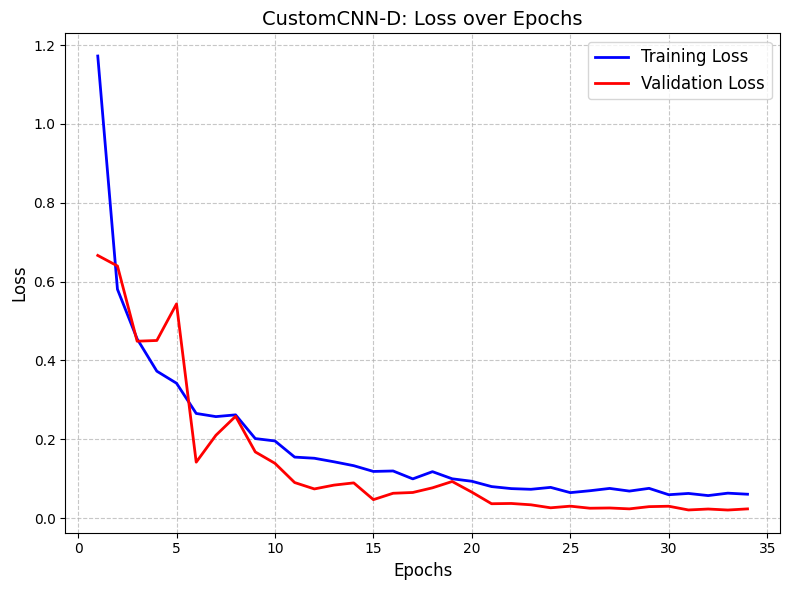

In [7]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from IPython.display import display

print("--- Phase 7: Training Proposed CustomCNN-D ---")

# Updated Plotting function to show graphs inline in Kaggle
def plot_and_show_curves(history, model_name="Custom CNN"):
    epochs = range(1, len(history['train_acc']) + 1)
    
    # 1. Plot Accuracy
    plt.figure(figsize=(8, 6))
    plt.plot(epochs, history['train_acc'], 'b-', label='Training Accuracy', linewidth=2)
    plt.plot(epochs, history['val_acc'], 'r-', label='Validation Accuracy', linewidth=2)
    plt.title(f'{model_name}: Accuracy over Epochs', fontsize=14)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Accuracy', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig(f'/kaggle/working/{model_name.lower().replace(" ", "_")}_accuracy.png', dpi=300)
    plt.show() # <--- This displays it inline
    plt.close()
    
    # 2. Plot Loss
    plt.figure(figsize=(8, 6))
    plt.plot(epochs, history['train_loss'], 'b-', label='Training Loss', linewidth=2)
    plt.plot(epochs, history['val_loss'], 'r-', label='Validation Loss', linewidth=2)
    plt.title(f'{model_name}: Loss over Epochs', fontsize=14)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig(f'/kaggle/working/{model_name.lower().replace(" ", "_")}_loss.png', dpi=300)
    plt.show() # <--- This displays it inline
    plt.close()

# 1. Initialize the selected Proposed Architecture (Variant D)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
proposed_model = CustomLightweightCNN(num_classes=6, use_se=True, use_residual=True)
proposed_model = proposed_model.to(device)

# 2. Setup Loss with the SAME Class Weights used in Baseline
criterion = nn.CrossEntropyLoss(weight=weights)

# 3. Setup Optimizer & Scheduler 
optimizer = optim.AdamW(proposed_model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)

# 4. Train the Model
best_proposed_model, proposed_history = train_model(
    proposed_model, 
    train_loader, 
    val_loader, 
    criterion, 
    optimizer, 
    scheduler, 
    num_epochs=40, 
    patience=7
)

# 5. Save the Weights and Show Plots
model_save_path = '/kaggle/working/custom_cnn_d_weights.pth'
torch.save(best_proposed_model.state_dict(), model_save_path)
print(f"Saved Proposed Model weights to {model_save_path}")

# Call the new inline plotting function
plot_and_show_curves(proposed_history, model_name="CustomCNN-D")

--- 1. COMPUTATIONAL EFFICIENCY (Proposed Model) ---
Measuring Latency (Warming up GPU...)
Total Parameters: 58,790
Model Size:       0.26 MB
GFLOPs:           0.1601
Latency (batch=1):2.34 ms ± 0.14 ms

--- 2. TEST SET EVALUATION ---
Test Accuracy:    0.9940
Test Macro-F1:    0.9953
Test Weighted-F1: 0.9941

--------------------------------------------------
CURRENT LEADERBOARD (Tables D & E Preview)
--------------------------------------------------
      Model  Parameters  Size_MB  GFLOPs  Latency_ms  Test_Accuracy  Test_Macro_F1  Test_Weighted_F1
BaselineCNN       94470     0.37  1.0350        0.87         0.8948         0.9132            0.8954
CustomCNN-D       58790     0.26  0.1601        2.34         0.9940         0.9953            0.9941


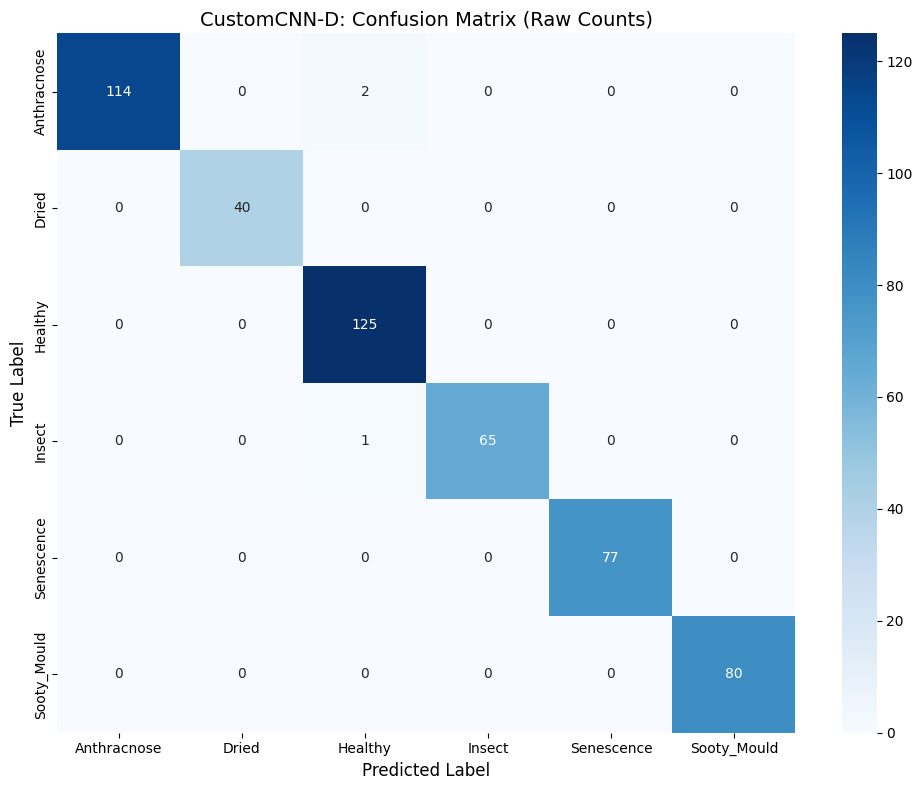

In [8]:
import torch
import time
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from thop import profile

# 1. Initialize Model and Load Weights
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_path = '/kaggle/working/custom_cnn_d_weights.pth'

proposed_model = CustomLightweightCNN(num_classes=6, use_se=True, use_residual=True)
proposed_model.load_state_dict(torch.load(model_path))
proposed_model.to(device)
proposed_model.eval()

print("--- 1. COMPUTATIONAL EFFICIENCY (Proposed Model) ---")

# A. Parameters
total_params = sum(p.numel() for p in proposed_model.parameters())

# B. Model Size (MB)
model_size_mb = os.path.getsize(model_path) / (1024 * 1024)

# C. FLOPs / MACs
dummy_input = torch.randn(1, 3, 224, 224).to(device)
macs, _ = profile(proposed_model, inputs=(dummy_input,), verbose=False)
flops_giga = (macs * 2) / 1e9

# D. Inference Latency (GPU Warmup & Measurement)
print("Measuring Latency (Warming up GPU...)")
for _ in range(50):
    _ = proposed_model(dummy_input)

start_events = [torch.cuda.Event(enable_timing=True) for _ in range(100)]
end_events = [torch.cuda.Event(enable_timing=True) for _ in range(100)]

with torch.no_grad():
    for i in range(100):
        start_events[i].record()
        _ = proposed_model(dummy_input)
        end_events[i].record()

torch.cuda.synchronize()
times = [s.elapsed_time(e) for s, e in zip(start_events, end_events)]
mean_latency = np.mean(times)
std_latency = np.std(times)

print(f"Total Parameters: {total_params:,}")
print(f"Model Size:       {model_size_mb:.2f} MB")
print(f"GFLOPs:           {flops_giga:.4f}")
print(f"Latency (batch=1):{mean_latency:.2f} ms ± {std_latency:.2f} ms\n")

# 2. Test Set Evaluation
print("--- 2. TEST SET EVALUATION ---")
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)
        
        with torch.amp.autocast('cuda'):
            outputs = proposed_model(inputs)
            _, preds = torch.max(outputs, 1)
            
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_acc = accuracy_score(all_labels, all_preds)
precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro', zero_division=0)
_, _, weighted_f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted', zero_division=0)

print(f"Test Accuracy:    {test_acc:.4f}")
print(f"Test Macro-F1:    {f1:.4f}")
print(f"Test Weighted-F1: {weighted_f1:.4f}\n")

# 3. Append Metrics to CSV
csv_path = '/kaggle/working/baseline_COMPUTATIONAL_EFFICIENCY.csv'

new_metrics = pd.DataFrame([{
    "Model": "CustomCNN-D",
    "Parameters": total_params,
    "Size_MB": round(model_size_mb, 2),
    "GFLOPs": round(flops_giga, 4),
    "Latency_ms": round(mean_latency, 2),
    "Test_Accuracy": round(test_acc, 4),
    "Test_Macro_F1": round(f1, 4),
    "Test_Weighted_F1": round(weighted_f1, 4)
}])

# Read existing, append, and save
existing_df = pd.read_csv(csv_path)
updated_df = pd.concat([existing_df, new_metrics], ignore_index=True)
updated_df.to_csv(csv_path, index=False)

print("-" * 50)
print("CURRENT LEADERBOARD (Tables D & E Preview)")
print("-" * 50)
print(updated_df.to_string(index=False))

# 4. Confusion Matrix (Raw Counts)
class_names = ['Anthracnose', 'Dried', 'Healthy', 'Insect', 'Senescence', 'Sooty_Mould']
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.title('CustomCNN-D: Confusion Matrix (Raw Counts)', fontsize=14)
plt.ylabel('True Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.tight_layout()
plt.savefig('/kaggle/working/custom_cnn_confusion_matrix.png', dpi=300)
plt.show()

--- Phase 8: Training MobileNetV3-Small (From Scratch) ---
Training on device: cuda

Epoch 1/40
---------------


/tmp/ipykernel_22/4030074278.py:64: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Train Loss: 1.0453 | Acc: 0.5271 | Macro-F1: 0.5308


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Val Loss: 1.8396 | Acc: 0.2306 | Macro-F1: 0.0625
  --> Best model updated!

Epoch 2/40
---------------


...

Val Loss: 0.2172 | Acc: 0.8966 | Macro-F1: 0.9075

Epoch 19/40
---------------


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Train Loss: 0.1196 | Acc: 0.9378 | Macro-F1: 0.9499


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Val Loss: 0.2433 | Acc: 0.8827 | Macro-F1: 0.8999

Early stopping triggered after 19 epochs.

Training complete. Best Val Macro-F1: 0.9485


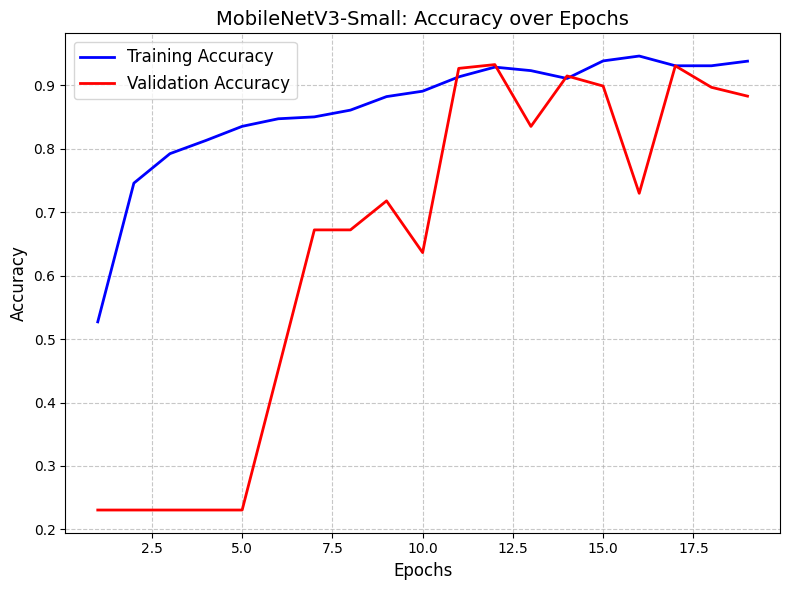

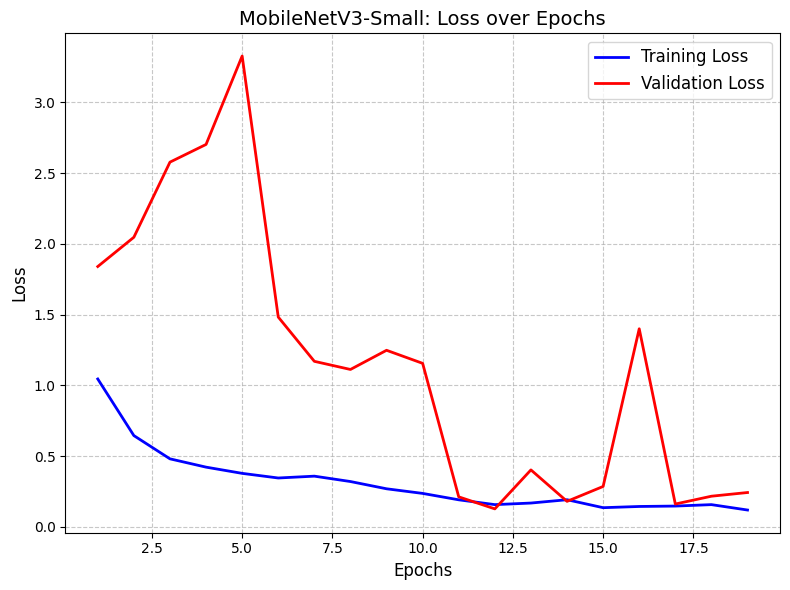


--- COMPUTATIONAL EFFICIENCY (MobileNetV3-Small) ---
Measuring Latency (Warming up GPU...)

--- TEST SET EVALUATION ---
--------------------------------------------------
CURRENT LEADERBOARD (Tables D & E Preview)
--------------------------------------------------
            Model  Parameters  Size_MB  GFLOPs  Latency_ms  Test_Accuracy  Test_Macro_F1  Test_Weighted_F1
      BaselineCNN       94470     0.37  1.0350        0.87         0.8948         0.9132            0.8954
      CustomCNN-D       58790     0.26  0.1601        2.34         0.9940         0.9953            0.9941
MobileNetV3-Small     1524006     5.95  0.1229        5.50         0.9524         0.9627            0.9525


In [9]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
import time
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from thop import profile

print("--- Phase 8: Training MobileNetV3-Small (From Scratch) ---")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Initialize MobileNetV3-Small
# weights=None explicitly trains from scratch (Blueprint: Experiment A)
mobilenet = models.mobilenet_v3_small(weights=None)

# Modify the classifier for our 6 classes
# MobileNetV3-Small classifier has a linear layer at index 3 with 1024 input features
in_features = mobilenet.classifier[3].in_features
mobilenet.classifier[3] = nn.Linear(in_features, 6)
mobilenet = mobilenet.to(device)

# 2. Setup Training (Identical to previous models)
criterion = nn.CrossEntropyLoss(weight=weights)
optimizer = optim.AdamW(mobilenet.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)

# 3. Train Model
best_mobilenet, mobilenet_history = train_model(
    mobilenet, 
    train_loader, 
    val_loader, 
    criterion, 
    optimizer, 
    scheduler, 
    num_epochs=40, 
    patience=7
)

# Save Weights and Plot Curves
model_path = '/kaggle/working/mobilenetv3_small_weights.pth'
torch.save(best_mobilenet.state_dict(), model_path)
plot_and_show_curves(mobilenet_history, model_name="MobileNetV3-Small")

# 4. COMPUTATIONAL EFFICIENCY
print("\n--- COMPUTATIONAL EFFICIENCY (MobileNetV3-Small) ---")
mobilenet.eval()

total_params = sum(p.numel() for p in mobilenet.parameters())
model_size_mb = os.path.getsize(model_path) / (1024 * 1024)

dummy_input = torch.randn(1, 3, 224, 224).to(device)
macs, _ = profile(mobilenet, inputs=(dummy_input,), verbose=False)
flops_giga = (macs * 2) / 1e9

print("Measuring Latency (Warming up GPU...)")
for _ in range(50): _ = mobilenet(dummy_input)

start_events = [torch.cuda.Event(enable_timing=True) for _ in range(100)]
end_events = [torch.cuda.Event(enable_timing=True) for _ in range(100)]

with torch.no_grad():
    for i in range(100):
        start_events[i].record()
        _ = mobilenet(dummy_input)
        end_events[i].record()

torch.cuda.synchronize()
times = [s.elapsed_time(e) for s, e in zip(start_events, end_events)]
mean_latency = np.mean(times)
std_latency = np.std(times)

# 5. TEST SET EVALUATION
print("\n--- TEST SET EVALUATION ---")
all_preds, all_labels = [], []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        with torch.amp.autocast('cuda'):
            outputs = mobilenet(inputs)
            _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_acc = accuracy_score(all_labels, all_preds)
_, _, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro', zero_division=0)
_, _, weighted_f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted', zero_division=0)

# 6. Append to Leaderboard
csv_path = '/kaggle/working/baseline_COMPUTATIONAL_EFFICIENCY.csv'
new_metrics = pd.DataFrame([{
    "Model": "MobileNetV3-Small",
    "Parameters": total_params,
    "Size_MB": round(model_size_mb, 2),
    "GFLOPs": round(flops_giga, 4),
    "Latency_ms": round(mean_latency, 2),
    "Test_Accuracy": round(test_acc, 4),
    "Test_Macro_F1": round(f1, 4),
    "Test_Weighted_F1": round(weighted_f1, 4)
}])

existing_df = pd.read_csv(csv_path)
updated_df = pd.concat([existing_df, new_metrics], ignore_index=True)
updated_df.to_csv(csv_path, index=False)

print("-" * 50)
print("CURRENT LEADERBOARD (Tables D & E Preview)")
print("-" * 50)
print(updated_df.to_string(index=False))

--- Phase 8: Training MobileNetV2 (From Scratch) ---
Training on device: cuda

Epoch 1/40
---------------


/tmp/ipykernel_22/4030074278.py:64: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Train Loss: 1.2963 | Acc: 0.3984 | Macro-F1: 0.4056


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Val Loss: 3.0542 | Acc: 0.1610 | Macro-F1: 0.1024
  --> Best model updated!

Epoch 2/40
---------------


...

Val Loss: 0.0311 | Acc: 0.9881 | Macro-F1: 0.9903

Epoch 40/40
---------------


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Train Loss: 0.0394 | Acc: 0.9821 | Macro-F1: 0.9861


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Val Loss: 0.0233 | Acc: 0.9901 | Macro-F1: 0.9914

Training complete. Best Val Macro-F1: 0.9930


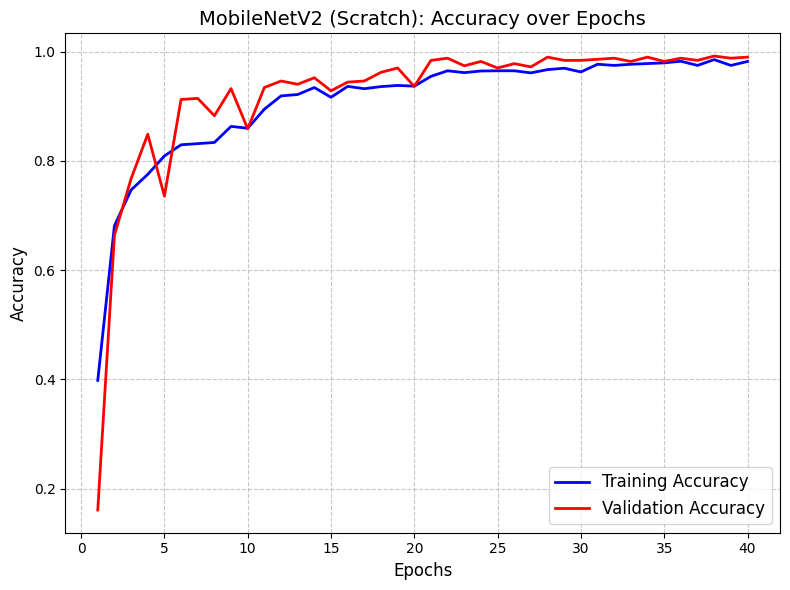

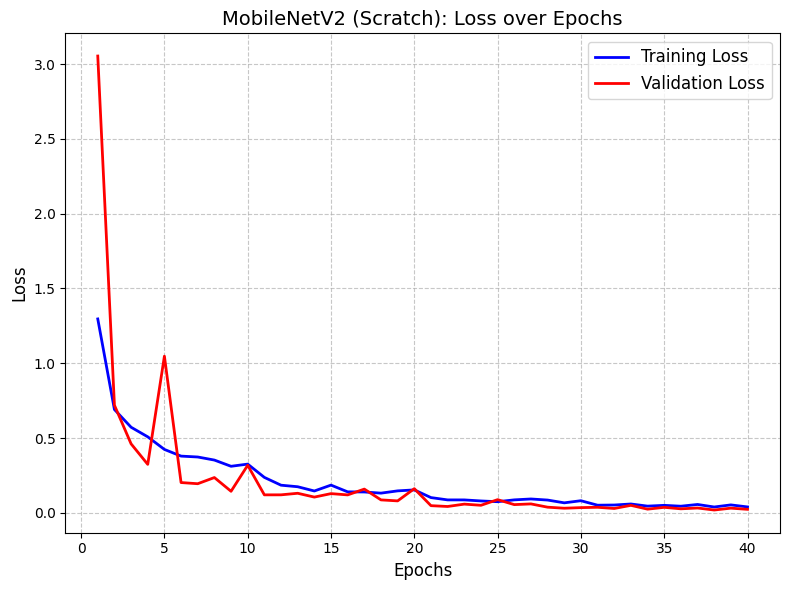


--- COMPUTATIONAL EFFICIENCY ---
Measuring Latency (Warming up GPU...)

--- TEST SET EVALUATION ---
--------------------------------------------------
CURRENT LEADERBOARD (Tables D & E Preview)
--------------------------------------------------
                Model  Parameters  Size_MB  GFLOPs  Latency_ms  Test_Accuracy  Test_Macro_F1  Test_Weighted_F1
          BaselineCNN       94470     0.37  1.0350        0.87         0.8948         0.9132            0.8954
          CustomCNN-D       58790     0.26  0.1601        2.34         0.9940         0.9953            0.9941
    MobileNetV3-Small     1524006     5.95  0.1229        5.50         0.9524         0.9627            0.9525
MobileNetV2 (Scratch)     2231558     8.75  0.6524        5.36         0.9940         0.9955            0.9941


In [10]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from thop import profile
from IPython.display import display

# Ensure plotting function is in memory
def plot_and_show_curves(history, model_name="Model"):
    epochs = range(1, len(history['train_acc']) + 1)
    
    # 1. Plot Accuracy
    plt.figure(figsize=(8, 6))
    plt.plot(epochs, history['train_acc'], 'b-', label='Training Accuracy', linewidth=2)
    plt.plot(epochs, history['val_acc'], 'r-', label='Validation Accuracy', linewidth=2)
    plt.title(f'{model_name}: Accuracy over Epochs', fontsize=14)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Accuracy', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig(f'/kaggle/working/{model_name.lower().replace(" ", "_").replace("(", "").replace(")", "")}_accuracy.png', dpi=300)
    plt.show() 
    plt.close()
    
    # 2. Plot Loss
    plt.figure(figsize=(8, 6))
    plt.plot(epochs, history['train_loss'], 'b-', label='Training Loss', linewidth=2)
    plt.plot(epochs, history['val_loss'], 'r-', label='Validation Loss', linewidth=2)
    plt.title(f'{model_name}: Loss over Epochs', fontsize=14)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig(f'/kaggle/working/{model_name.lower().replace(" ", "_").replace("(", "").replace(")", "")}_loss.png', dpi=300)
    plt.show() 
    plt.close()

print("--- Phase 8: Training MobileNetV2 (From Scratch) ---")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Initialize MobileNetV2 (weights=None means train from scratch)
mobilenet_v2 = models.mobilenet_v2(weights=None)
in_features = mobilenet_v2.classifier[1].in_features
mobilenet_v2.classifier[1] = nn.Linear(in_features, 6)
mobilenet_v2 = mobilenet_v2.to(device)

# 2. Setup Training
criterion = nn.CrossEntropyLoss(weight=weights)
optimizer = optim.AdamW(mobilenet_v2.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)

# 3. Train Model
best_mbv2, mbv2_history = train_model(
    mobilenet_v2, 
    train_loader, 
    val_loader, 
    criterion, 
    optimizer, 
    scheduler, 
    num_epochs=40, 
    patience=7
)

# Save Weights and Plot Curves
model_path = '/kaggle/working/mobilenetv2_scratch_weights.pth'
torch.save(best_mbv2.state_dict(), model_path)
plot_and_show_curves(mbv2_history, model_name="MobileNetV2 (Scratch)")

# 4. COMPUTATIONAL EFFICIENCY
print("\n--- COMPUTATIONAL EFFICIENCY ---")
mobilenet_v2.eval()

total_params = sum(p.numel() for p in mobilenet_v2.parameters())
model_size_mb = os.path.getsize(model_path) / (1024 * 1024)

dummy_input = torch.randn(1, 3, 224, 224).to(device)
macs, _ = profile(mobilenet_v2, inputs=(dummy_input,), verbose=False)
flops_giga = (macs * 2) / 1e9

print("Measuring Latency (Warming up GPU...)")
for _ in range(50): _ = mobilenet_v2(dummy_input)

start_events = [torch.cuda.Event(enable_timing=True) for _ in range(100)]
end_events = [torch.cuda.Event(enable_timing=True) for _ in range(100)]

with torch.no_grad():
    for i in range(100):
        start_events[i].record()
        _ = mobilenet_v2(dummy_input)
        end_events[i].record()

torch.cuda.synchronize()
times = [s.elapsed_time(e) for s, e in zip(start_events, end_events)]
mean_latency = np.mean(times)

# 5. TEST SET EVALUATION
print("\n--- TEST SET EVALUATION ---")
all_preds, all_labels = [], []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        with torch.amp.autocast('cuda'):
            outputs = mobilenet_v2(inputs)
            _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_acc = accuracy_score(all_labels, all_preds)
_, _, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro', zero_division=0)
_, _, weighted_f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted', zero_division=0)

# 6. Append to Leaderboard
csv_path = '/kaggle/working/baseline_COMPUTATIONAL_EFFICIENCY.csv'
new_metrics = pd.DataFrame([{
    "Model": "MobileNetV2 (Scratch)",
    "Parameters": total_params,
    "Size_MB": round(model_size_mb, 2),
    "GFLOPs": round(flops_giga, 4),
    "Latency_ms": round(mean_latency, 2),
    "Test_Accuracy": round(test_acc, 4),
    "Test_Macro_F1": round(f1, 4),
    "Test_Weighted_F1": round(weighted_f1, 4)
}])

existing_df = pd.read_csv(csv_path)
updated_df = pd.concat([existing_df, new_metrics], ignore_index=True)
updated_df.to_csv(csv_path, index=False)

print("-" * 50)
print("CURRENT LEADERBOARD (Tables D & E Preview)")
print("-" * 50)
print(updated_df.to_string(index=False))

--- Phase 8: Training EfficientNet-B2 (From Scratch) ---
Training on device: cuda

Epoch 1/40
---------------


/tmp/ipykernel_22/4030074278.py:64: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Train Loss: 1.4417 | Acc: 0.3622 | Macro-F1: 0.3768


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Val Loss: 1.0104 | Acc: 0.5109 | Macro-F1: 0.4978
  --> Best model updated!

Epoch 2/40
---------------


...

Val Loss: 0.0044 | Acc: 1.0000 | Macro-F1: 1.0000

Epoch 40/40
---------------


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Train Loss: 0.0268 | Acc: 0.9893 | Macro-F1: 0.9910


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Val Loss: 0.0085 | Acc: 0.9960 | Macro-F1: 0.9968

Training complete. Best Val Macro-F1: 1.0000


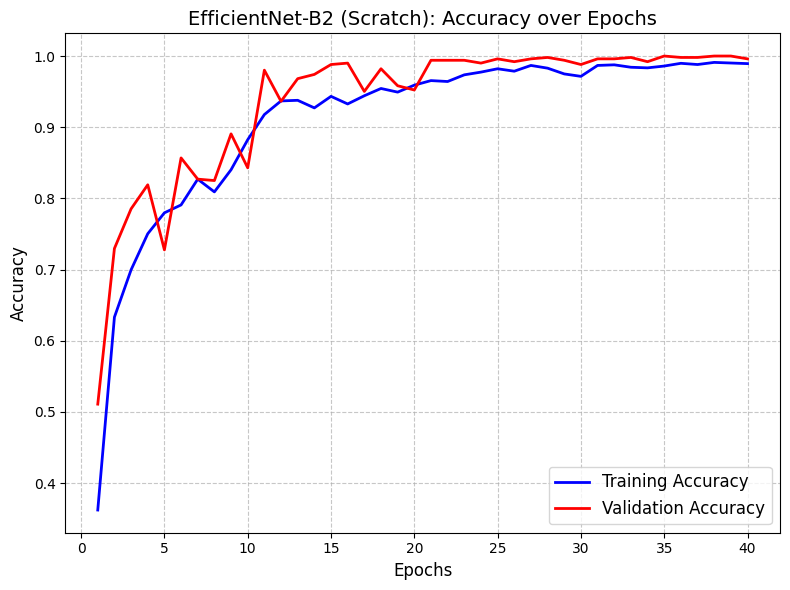

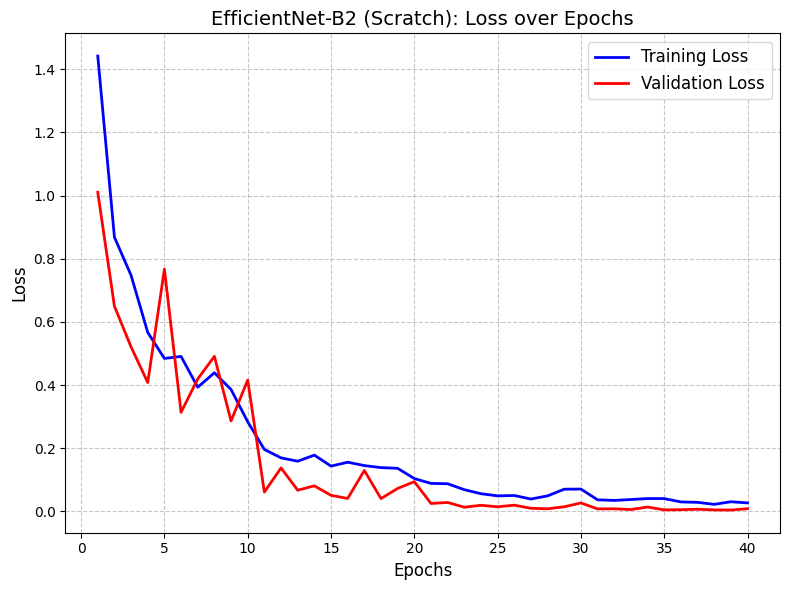


--- COMPUTATIONAL EFFICIENCY ---
Measuring Latency (Warming up GPU...)

--- TEST SET EVALUATION ---
--------------------------------------------------
CURRENT LEADERBOARD (Tables D & E Preview)
--------------------------------------------------
                    Model  Parameters  Size_MB  GFLOPs  Latency_ms  Test_Accuracy  Test_Macro_F1  Test_Weighted_F1
              BaselineCNN       94470     0.37  1.0350        0.87         0.8948         0.9132            0.8954
              CustomCNN-D       58790     0.26  0.1601        2.34         0.9940         0.9953            0.9941
        MobileNetV3-Small     1524006     5.95  0.1229        5.50         0.9524         0.9627            0.9525
    MobileNetV2 (Scratch)     2231558     8.75  0.6524        5.36         0.9940         0.9955            0.9941
EfficientNet-B2 (Scratch)     7709448    29.85  1.4011       12.33         0.9940         0.9954            0.9940


In [11]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from thop import profile
from IPython.display import display

# Ensure plotting function is in memory
def plot_and_show_curves(history, model_name="Model"):
    epochs = range(1, len(history['train_acc']) + 1)
    
    # 1. Plot Accuracy
    plt.figure(figsize=(8, 6))
    plt.plot(epochs, history['train_acc'], 'b-', label='Training Accuracy', linewidth=2)
    plt.plot(epochs, history['val_acc'], 'r-', label='Validation Accuracy', linewidth=2)
    plt.title(f'{model_name}: Accuracy over Epochs', fontsize=14)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Accuracy', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    # Safely format filename
    safe_name = model_name.lower().replace(" ", "_").replace("(", "").replace(")", "").replace("-", "_")
    plt.savefig(f'/kaggle/working/{safe_name}_accuracy.png', dpi=300)
    plt.show() 
    plt.close()
    
    # 2. Plot Loss
    plt.figure(figsize=(8, 6))
    plt.plot(epochs, history['train_loss'], 'b-', label='Training Loss', linewidth=2)
    plt.plot(epochs, history['val_loss'], 'r-', label='Validation Loss', linewidth=2)
    plt.title(f'{model_name}: Loss over Epochs', fontsize=14)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig(f'/kaggle/working/{safe_name}_loss.png', dpi=300)
    plt.show() 
    plt.close()

print("--- Phase 8: Training EfficientNet-B2 (From Scratch) ---")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Initialize EfficientNet-B2 (weights=None means train from scratch)
efficientnet = models.efficientnet_b2(weights=None)

# EfficientNet classifier is a Sequential block. The Linear layer is at index 1.
in_features = efficientnet.classifier[1].in_features
efficientnet.classifier[1] = nn.Linear(in_features, 6)
efficientnet = efficientnet.to(device)

# 2. Setup Training
criterion = nn.CrossEntropyLoss(weight=weights)
optimizer = optim.AdamW(efficientnet.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)

# 3. Train Model
best_eff, eff_history = train_model(
    efficientnet, 
    train_loader, 
    val_loader, 
    criterion, 
    optimizer, 
    scheduler, 
    num_epochs=40, 
    patience=7
)

# Save Weights and Plot Curves
model_path = '/kaggle/working/efficientnet_b2_scratch_weights.pth'
torch.save(best_eff.state_dict(), model_path)
plot_and_show_curves(eff_history, model_name="EfficientNet-B2 (Scratch)")

# 4. COMPUTATIONAL EFFICIENCY
print("\n--- COMPUTATIONAL EFFICIENCY ---")
efficientnet.eval()

total_params = sum(p.numel() for p in efficientnet.parameters())
model_size_mb = os.path.getsize(model_path) / (1024 * 1024)

dummy_input = torch.randn(1, 3, 224, 224).to(device)
macs, _ = profile(efficientnet, inputs=(dummy_input,), verbose=False)
flops_giga = (macs * 2) / 1e9

print("Measuring Latency (Warming up GPU...)")
for _ in range(50): _ = efficientnet(dummy_input)

start_events = [torch.cuda.Event(enable_timing=True) for _ in range(100)]
end_events = [torch.cuda.Event(enable_timing=True) for _ in range(100)]

with torch.no_grad():
    for i in range(100):
        start_events[i].record()
        _ = efficientnet(dummy_input)
        end_events[i].record()

torch.cuda.synchronize()
times = [s.elapsed_time(e) for s, e in zip(start_events, end_events)]
mean_latency = np.mean(times)

# 5. TEST SET EVALUATION
print("\n--- TEST SET EVALUATION ---")
all_preds, all_labels = [], []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        with torch.amp.autocast('cuda'):
            outputs = efficientnet(inputs)
            _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_acc = accuracy_score(all_labels, all_preds)
_, _, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro', zero_division=0)
_, _, weighted_f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted', zero_division=0)

# 6. Append to Leaderboard
csv_path = '/kaggle/working/baseline_COMPUTATIONAL_EFFICIENCY.csv'
new_metrics = pd.DataFrame([{
    "Model": "EfficientNet-B2 (Scratch)",
    "Parameters": total_params,
    "Size_MB": round(model_size_mb, 2),
    "GFLOPs": round(flops_giga, 4),
    "Latency_ms": round(mean_latency, 2),
    "Test_Accuracy": round(test_acc, 4),
    "Test_Macro_F1": round(f1, 4),
    "Test_Weighted_F1": round(weighted_f1, 4)
}])

existing_df = pd.read_csv(csv_path)
updated_df = pd.concat([existing_df, new_metrics], ignore_index=True)
updated_df.to_csv(csv_path, index=False)

print("-" * 50)
print("CURRENT LEADERBOARD (Tables D & E Preview)")
print("-" * 50)
print(updated_df.to_string(index=False))

--- Phase 15: Transfer Learning (Linear Probing) ---

Starting MobileNetV3-Small (TL)
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 82.3MB/s]

Training on device: cuda

Epoch 1/20
---------------



/tmp/ipykernel_22/4030074278.py:64: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Train Loss: 0.9059 | Acc: 0.7124 | Macro-F1: 0.7187


...

Val Loss: 0.1227 | Acc: 0.9523 | Macro-F1: 0.9599

Epoch 20/20
---------------


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Train Loss: 0.1621 | Acc: 0.9416 | Macro-F1: 0.9484


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Val Loss: 0.1223 | Acc: 0.9583 | Macro-F1: 0.9647
  --> Best model updated!

Training complete. Best Val Macro-F1: 0.9647


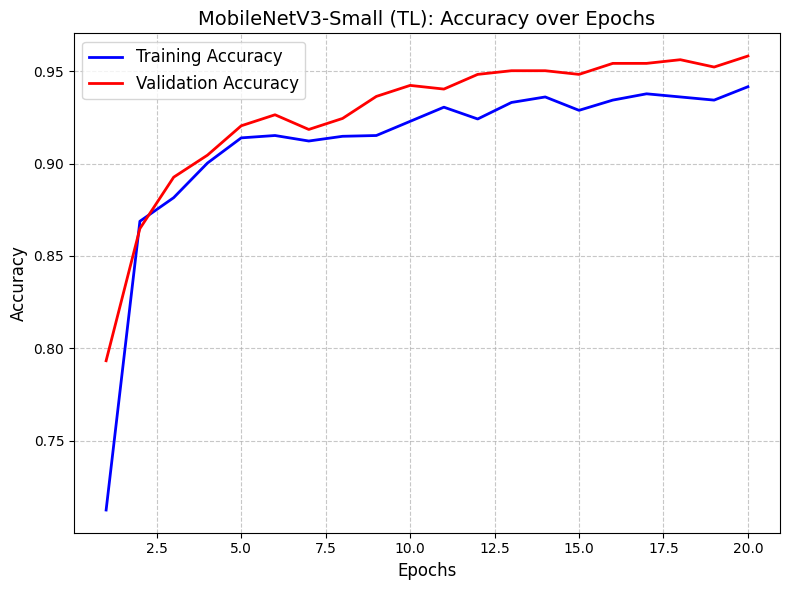

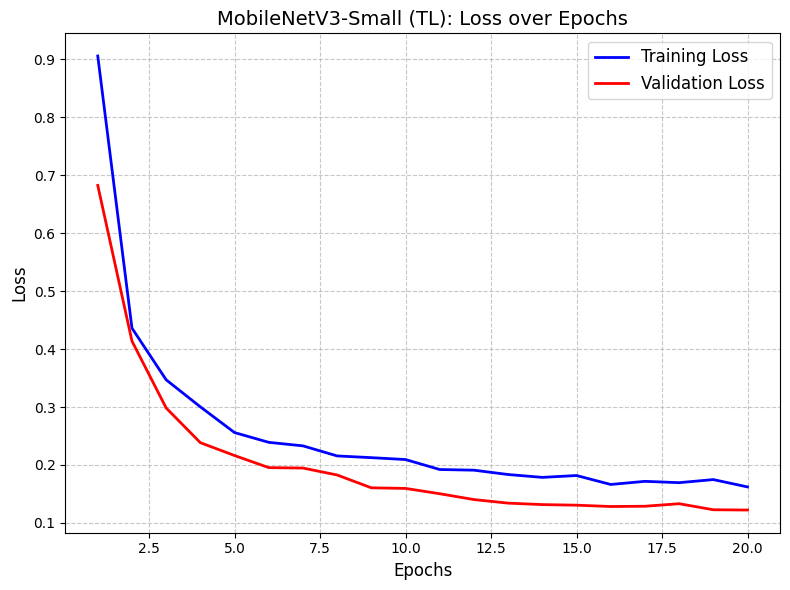


Starting MobileNetV2 (TL)
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 102MB/s] 
/tmp/ipykernel_22/4030074278.py:64: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()


Training on device: cuda

Epoch 1/20
---------------


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Train Loss: 1.0275 | Acc: 0.7512 | Macro-F1: 0.7577


...

Val Loss: 0.1445 | Acc: 0.9563 | Macro-F1: 0.9605

Epoch 18/20
---------------


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Train Loss: 0.1386 | Acc: 0.9510 | Macro-F1: 0.9559


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Val Loss: 0.1378 | Acc: 0.9602 | Macro-F1: 0.9640

Early stopping triggered after 18 epochs.

Training complete. Best Val Macro-F1: 0.9644


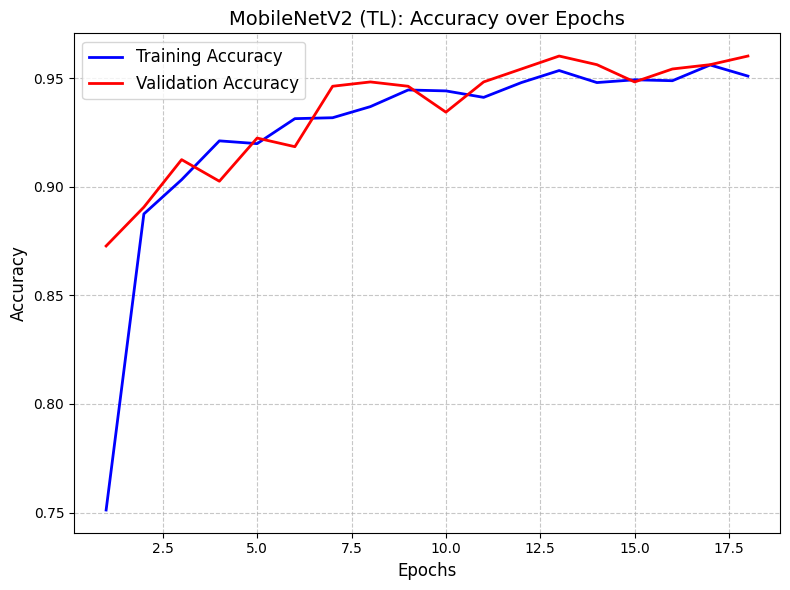

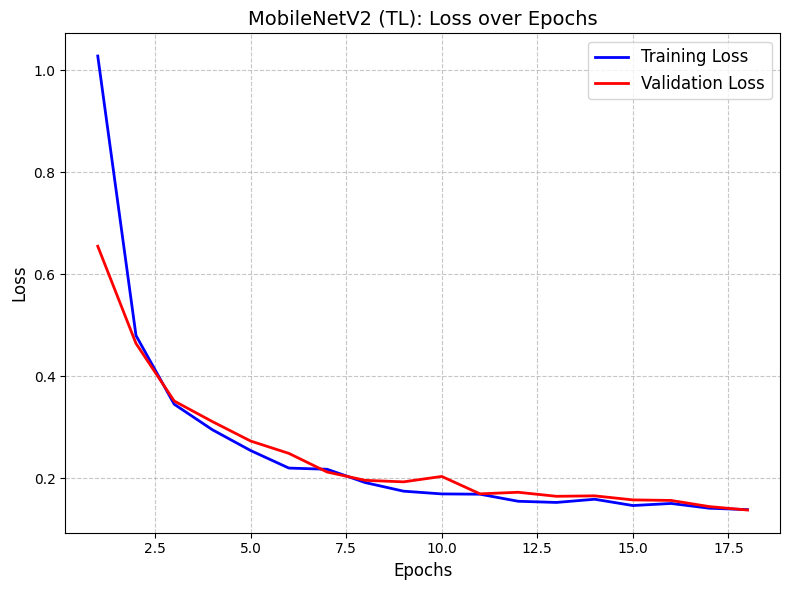


Starting EfficientNet-B2 (TL)
Downloading: "https://download.pytorch.org/models/efficientnet_b2_rwightman-c35c1473.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b2_rwightman-c35c1473.pth


100%|██████████| 35.2M/35.2M [00:00<00:00, 142MB/s]
/tmp/ipykernel_22/4030074278.py:64: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()


Training on device: cuda

Epoch 1/20
---------------


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Train Loss: 0.9570 | Acc: 0.7490 | Macro-F1: 0.7538


...

Val Loss: 0.1439 | Acc: 0.9602 | Macro-F1: 0.9603

Epoch 20/20
---------------


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Train Loss: 0.1703 | Acc: 0.9391 | Macro-F1: 0.9456


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Val Loss: 0.1392 | Acc: 0.9622 | Macro-F1: 0.9638

Training complete. Best Val Macro-F1: 0.9652


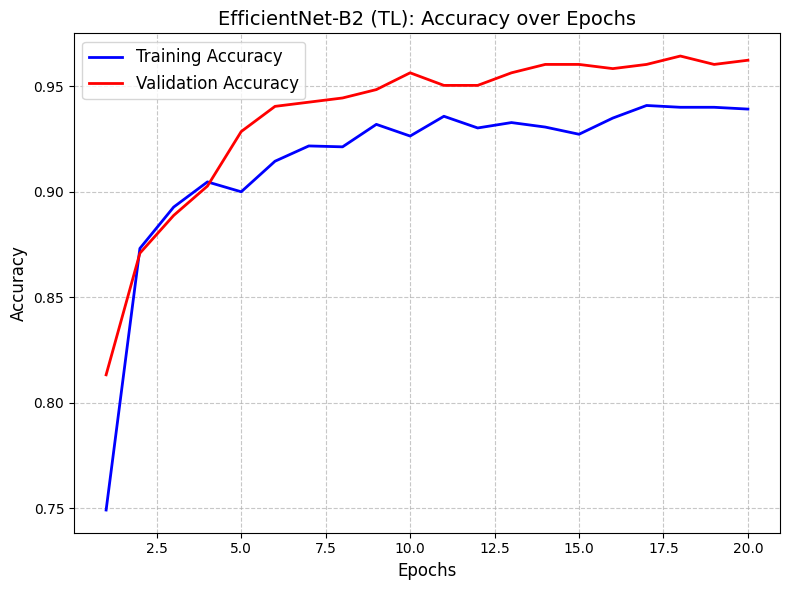

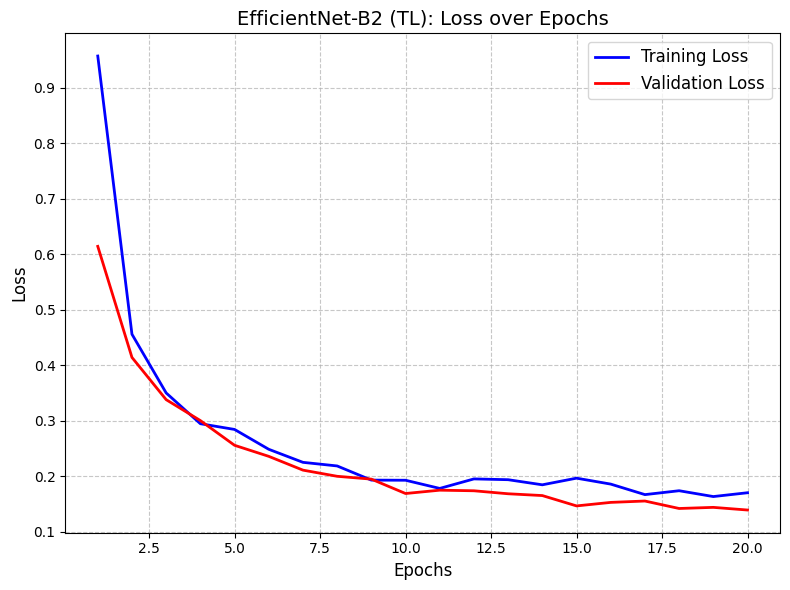


--------------------------------------------------
FINAL COMPREHENSIVE LEADERBOARD
--------------------------------------------------
                    Model  Parameters  Size_MB  GFLOPs  Latency_ms  Test_Accuracy  Test_Macro_F1  Test_Weighted_F1
              BaselineCNN       94470     0.37  1.0350        0.87         0.8948         0.9132            0.8954
              CustomCNN-D       58790     0.26  0.1601        2.34         0.9940         0.9953            0.9941
        MobileNetV3-Small     1524006     5.95  0.1229        5.50         0.9524         0.9627            0.9525
    MobileNetV2 (Scratch)     2231558     8.75  0.6524        5.36         0.9940         0.9955            0.9941
EfficientNet-B2 (Scratch)     7709448    29.85  1.4011       12.33         0.9940         0.9954            0.9940
   MobileNetV3-Small (TL)     1524006     5.95  0.1229        5.64         0.9504         0.9568            0.9502
         MobileNetV2 (TL)     2231558     8.75  0.6524      

In [12]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
import numpy as np
import pandas as pd
import os
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from thop import profile
import gc

print("--- Phase 15: Transfer Learning (Linear Probing) ---")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
csv_path = '/kaggle/working/baseline_COMPUTATIONAL_EFFICIENCY.csv'

# Define the models we want to fine-tune
tl_configs = [
    {"name": "MobileNetV3-Small (TL)", "loader": models.mobilenet_v3_small},
    {"name": "MobileNetV2 (TL)", "loader": models.mobilenet_v2},
    {"name": "EfficientNet-B2 (TL)", "loader": models.efficientnet_b2}
]

for config in tl_configs:
    model_name = config["name"]
    print(f"\n{'='*50}\nStarting {model_name}\n{'='*50}")
    
    # 1. Load Pretrained Weights
    model = config["loader"](weights='DEFAULT')
    
    # 2. Freeze all layers
    for param in model.parameters():
        param.requires_grad = False
        
    # 3. Replace Classifier (automatically sets requires_grad=True for this layer)
    if "MobileNetV3" in model_name:
        in_feat = model.classifier[3].in_features
        model.classifier[3] = nn.Linear(in_feat, 6)
    elif "MobileNetV2" in model_name:
        in_feat = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(in_feat, 6)
    elif "EfficientNet" in model_name:
        in_feat = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(in_feat, 6)
        
    model = model.to(device)
    
    # 4. Setup Training (Only pass parameters that require gradients!)
    criterion = nn.CrossEntropyLoss(weight=weights)
    trainable_params = filter(lambda p: p.requires_grad, model.parameters())
    optimizer = optim.AdamW(trainable_params, lr=1e-3, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)
    
    # 5. Train Model
    best_model, history = train_model(
        model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=20, patience=5
    )
    
    # Save and Plot
    safe_name = model_name.lower().replace(" ", "_").replace("(", "").replace(")", "").replace("-", "_")
    model_path = f'/kaggle/working/{safe_name}_weights.pth'
    torch.save(best_model.state_dict(), model_path)
    plot_and_show_curves(history, model_name=model_name)
    
    # 6. Computational Efficiency (Trainable Params only)
    model.eval()
    total_params = sum(p.numel() for p in model.parameters())
    # Note: We still calculate full GFLOPs and latency because the whole model runs during inference
    model_size_mb = os.path.getsize(model_path) / (1024 * 1024)
    
    dummy_input = torch.randn(1, 3, 224, 224).to(device)
    macs, _ = profile(model, inputs=(dummy_input,), verbose=False)
    flops_giga = (macs * 2) / 1e9
    
    # Warmup and Latency
    for _ in range(50): _ = model(dummy_input)
    start_events = [torch.cuda.Event(enable_timing=True) for _ in range(100)]
    end_events = [torch.cuda.Event(enable_timing=True) for _ in range(100)]
    
    with torch.no_grad():
        for i in range(100):
            start_events[i].record()
            _ = model(dummy_input)
            end_events[i].record()
            
    torch.cuda.synchronize()
    times = [s.elapsed_time(e) for s, e in zip(start_events, end_events)]
    mean_latency = np.mean(times)
    
    # 7. Test Set Evaluation
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            with torch.amp.autocast('cuda'):
                outputs = model(inputs)
                _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            
    test_acc = accuracy_score(all_labels, all_preds)
    _, _, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro', zero_division=0)
    _, _, weighted_f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted', zero_division=0)
    
    # 8. Append to Leaderboard
    new_metrics = pd.DataFrame([{
        "Model": model_name,
        "Parameters": total_params,
        "Size_MB": round(model_size_mb, 2),
        "GFLOPs": round(flops_giga, 4),
        "Latency_ms": round(mean_latency, 2),
        "Test_Accuracy": round(test_acc, 4),
        "Test_Macro_F1": round(f1, 4),
        "Test_Weighted_F1": round(weighted_f1, 4)
    }])
    
    existing_df = pd.read_csv(csv_path)
    updated_df = pd.concat([existing_df, new_metrics], ignore_index=True)
    updated_df.to_csv(csv_path, index=False)
    
    # Memory cleanup before next model
    del model, best_model, optimizer
    torch.cuda.empty_cache()
    gc.collect()

print("\n" + "-" * 50)
print("FINAL COMPREHENSIVE LEADERBOARD")
print("-" * 50)
print(updated_df.to_string(index=False))

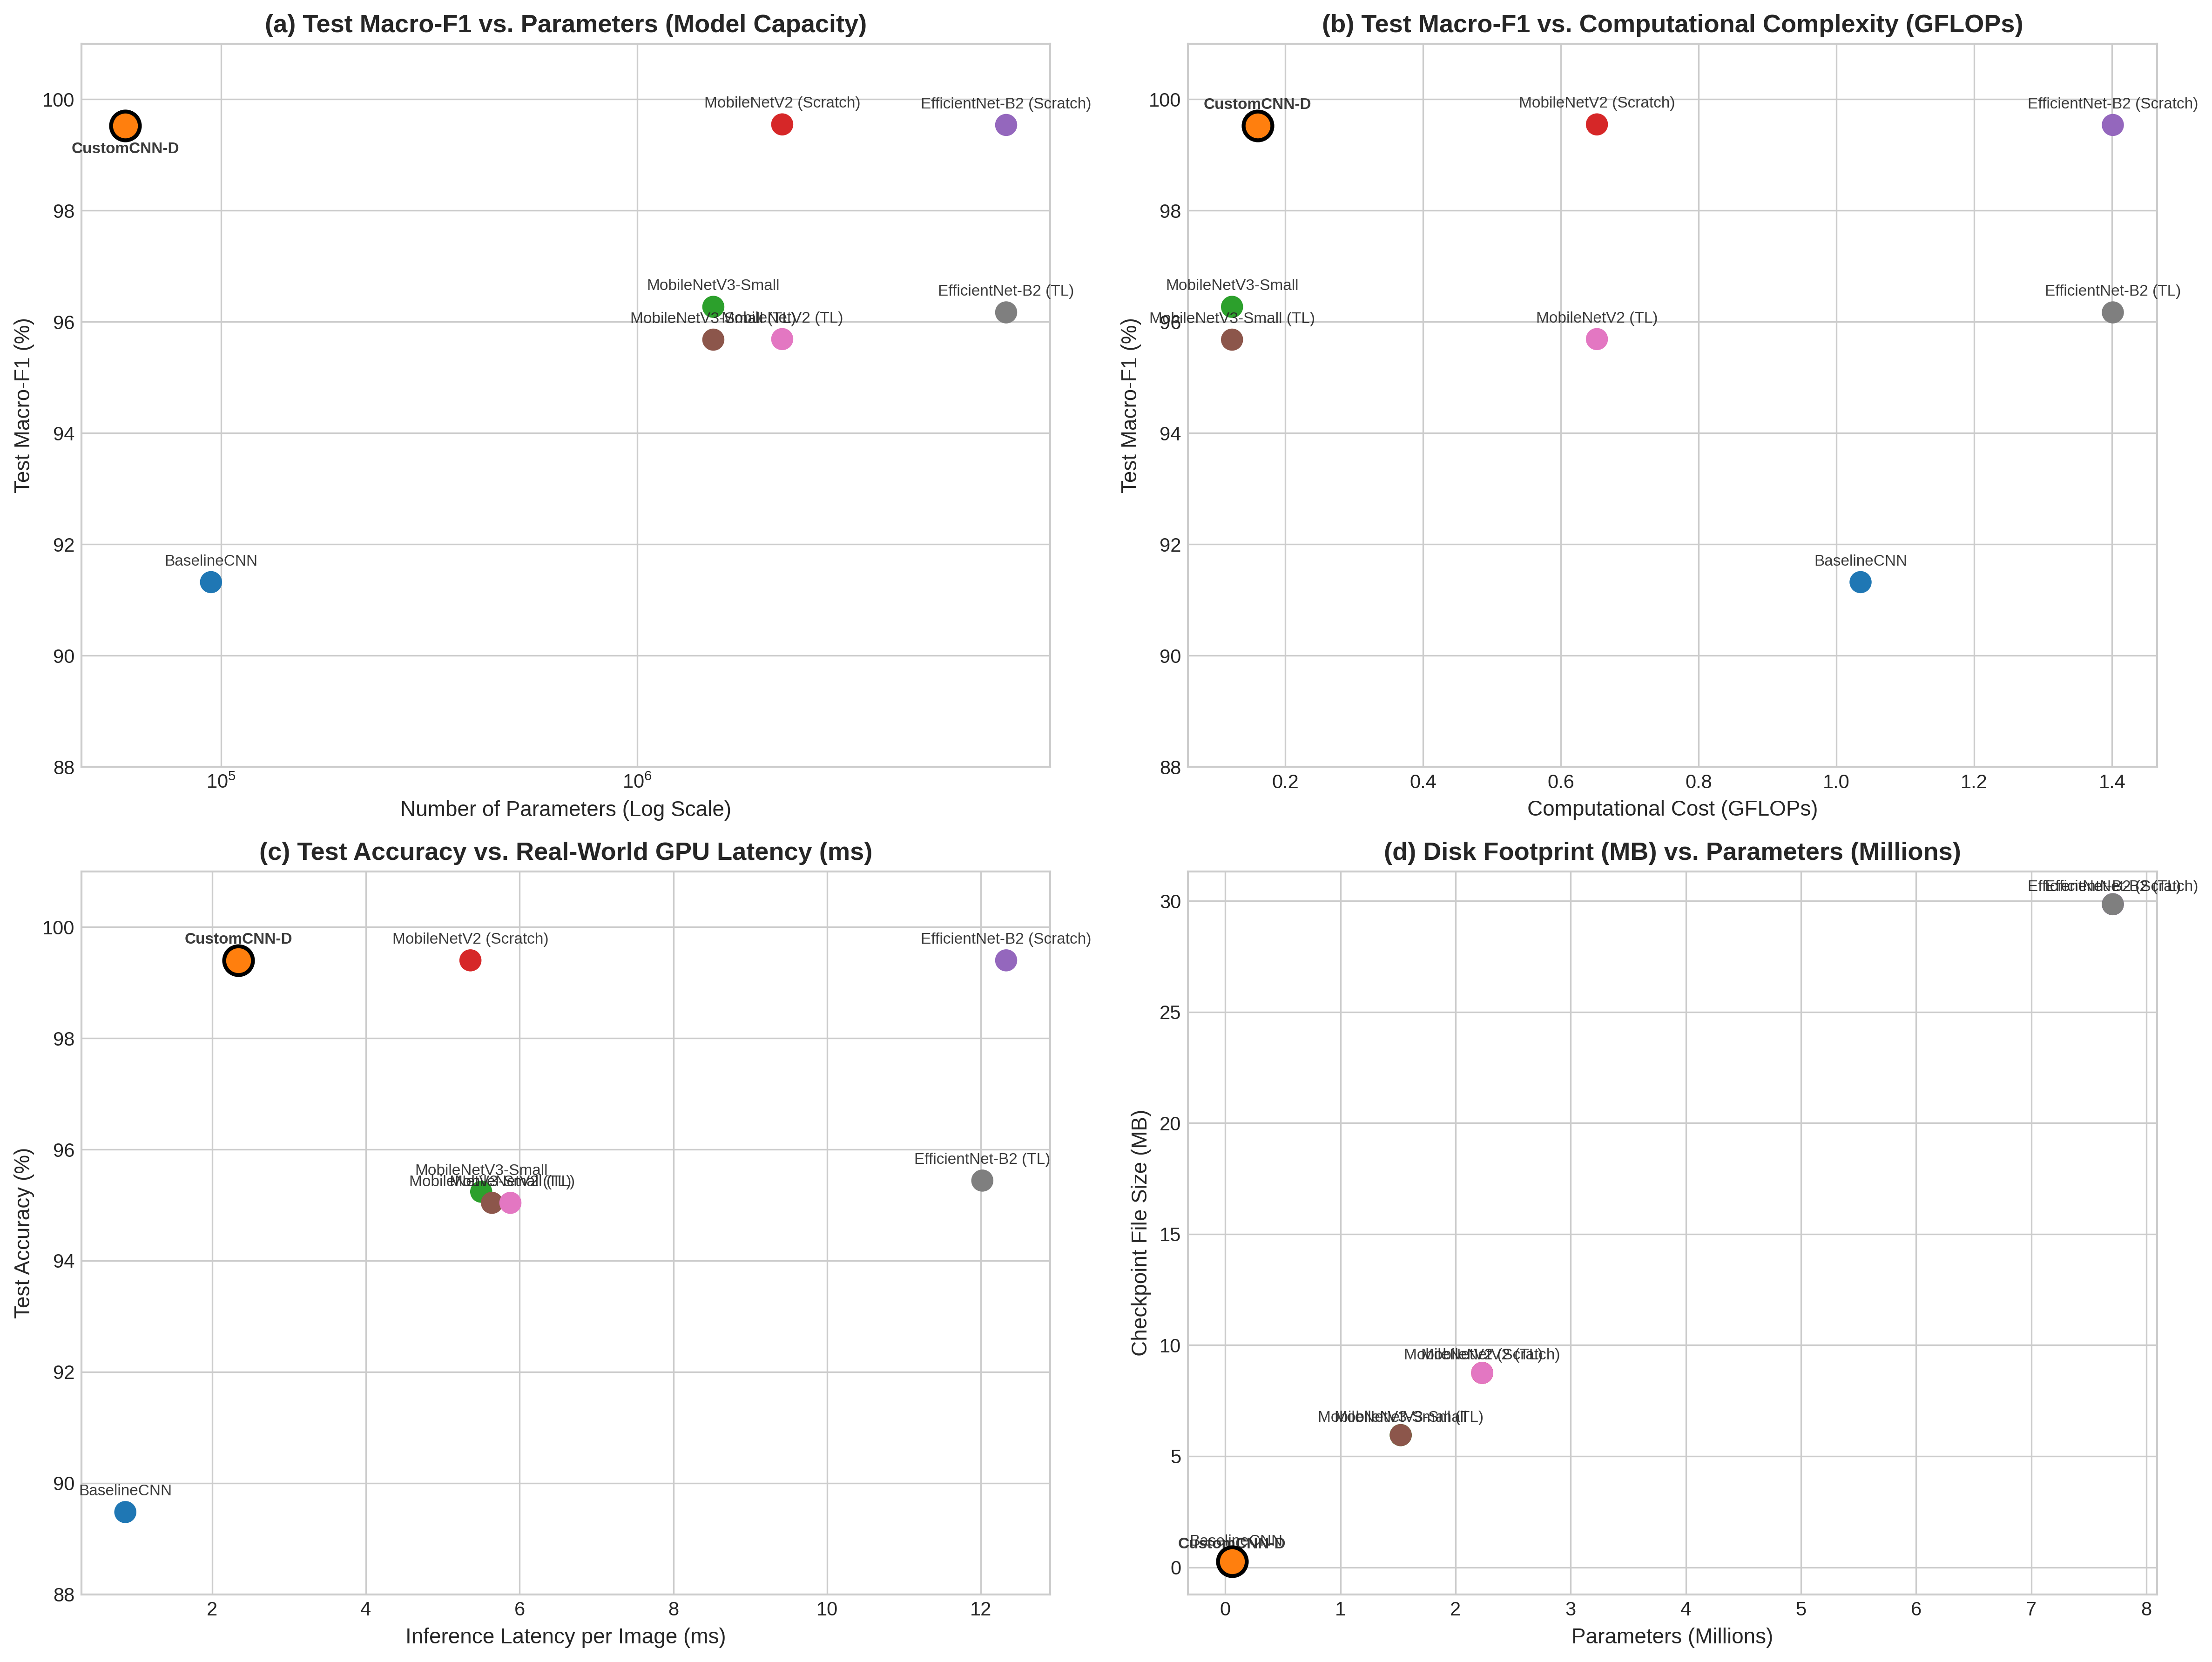

Saved publication trade-off figure to: /kaggle/working/figure3_pareto_efficiency_analysis.png


In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set publication style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axs = plt.subplots(2, 2, figsize=(16, 12), dpi=300)

csv_path = '/kaggle/working/baseline_COMPUTATIONAL_EFFICIENCY.csv'
df = pd.read_csv(csv_path)

# Assign distinct markers and colors
palette = sns.color_palette("tab10", len(df))
model_colors = {model: palette[i] for i, model in enumerate(df['Model'])}

# -------------------------------------------------------------
# 1. Macro-F1 vs. Parameters (Log Scale)
# -------------------------------------------------------------
ax1 = axs[0, 0]
for idx, row in df.iterrows():
    is_custom = "CustomCNN" in row['Model']
    ax1.scatter(
        row['Parameters'], row['Test_Macro_F1'] * 100, 
        s=220 if is_custom else 130, 
        color=model_colors[row['Model']], 
        edgecolor='black' if is_custom else 'none',
        linewidth=2 if is_custom else 0,
        zorder=5 if is_custom else 3,
        label=row['Model']
    )
    # Annotate labels
    offset_y = 0.3 if not is_custom else -0.5
    ax1.annotate(row['Model'], (row['Parameters'], row['Test_Macro_F1'] * 100 + offset_y),
                 fontsize=8, fontweight='bold' if is_custom else 'normal',
                 ha='center', alpha=0.9)

ax1.set_xscale('log')
ax1.set_title('(a) Test Macro-F1 vs. Parameters (Model Capacity)', fontsize=13, fontweight='bold')
ax1.set_xlabel('Number of Parameters (Log Scale)', fontsize=11)
ax1.set_ylabel('Test Macro-F1 (%)', fontsize=11)
ax1.set_ylim(88, 101)

# -------------------------------------------------------------
# 2. Macro-F1 vs. GFLOPs
# -------------------------------------------------------------
ax2 = axs[0, 1]
for idx, row in df.iterrows():
    is_custom = "CustomCNN" in row['Model']
    ax2.scatter(
        row['GFLOPs'], row['Test_Macro_F1'] * 100, 
        s=220 if is_custom else 130, 
        color=model_colors[row['Model']], 
        edgecolor='black' if is_custom else 'none',
        linewidth=2 if is_custom else 0,
        zorder=5 if is_custom else 3
    )
    ax2.annotate(row['Model'], (row['GFLOPs'], row['Test_Macro_F1'] * 100 + 0.3),
                 fontsize=8, fontweight='bold' if is_custom else 'normal',
                 ha='center', alpha=0.9)

ax2.set_title('(b) Test Macro-F1 vs. Computational Complexity (GFLOPs)', fontsize=13, fontweight='bold')
ax2.set_xlabel('Computational Cost (GFLOPs)', fontsize=11)
ax2.set_ylabel('Test Macro-F1 (%)', fontsize=11)
ax2.set_ylim(88, 101)

# -------------------------------------------------------------
# 3. Test Accuracy vs. GPU Inference Latency
# -------------------------------------------------------------
ax3 = axs[1, 0]
for idx, row in df.iterrows():
    is_custom = "CustomCNN" in row['Model']
    ax3.scatter(
        row['Latency_ms'], row['Test_Accuracy'] * 100, 
        s=220 if is_custom else 130, 
        color=model_colors[row['Model']], 
        edgecolor='black' if is_custom else 'none',
        linewidth=2 if is_custom else 0,
        zorder=5 if is_custom else 3
    )
    ax3.annotate(row['Model'], (row['Latency_ms'], row['Test_Accuracy'] * 100 + 0.3),
                 fontsize=8, fontweight='bold' if is_custom else 'normal',
                 ha='center', alpha=0.9)

ax3.set_title('(c) Test Accuracy vs. Real-World GPU Latency (ms)', fontsize=13, fontweight='bold')
ax3.set_xlabel('Inference Latency per Image (ms)', fontsize=11)
ax3.set_ylabel('Test Accuracy (%)', fontsize=11)
ax3.set_ylim(88, 101)

# -------------------------------------------------------------
# 4. Model Size on Disk (MB) vs. Parameters
# -------------------------------------------------------------
ax4 = axs[1, 1]
for idx, row in df.iterrows():
    is_custom = "CustomCNN" in row['Model']
    ax4.scatter(
        row['Parameters'] / 1e6, row['Size_MB'], 
        s=220 if is_custom else 130, 
        color=model_colors[row['Model']], 
        edgecolor='black' if is_custom else 'none',
        linewidth=2 if is_custom else 0,
        zorder=5 if is_custom else 3
    )
    ax4.annotate(row['Model'], (row['Parameters'] / 1e6, row['Size_MB'] + 0.6),
                 fontsize=8, fontweight='bold' if is_custom else 'normal',
                 ha='center', alpha=0.9)

ax4.set_title('(d) Disk Footprint (MB) vs. Parameters (Millions)', fontsize=13, fontweight='bold')
ax4.set_xlabel('Parameters (Millions)', fontsize=11)
ax4.set_ylabel('Checkpoint File Size (MB)', fontsize=11)

plt.tight_layout()
output_figure_path = '/kaggle/working/figure3_pareto_efficiency_analysis.png'
plt.savefig(output_figure_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Saved publication trade-off figure to: {output_figure_path}")

--- Phase 23: Executing Ablation Study ---

Training CustomCNN-A (Base DW)
Training on device: cuda

Epoch 1/40
---------------


/tmp/ipykernel_22/4030074278.py:64: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Train Loss: 1.1460 | Acc: 0.5032 | Macro-F1: 0.5303


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Val Loss: 0.7216 | Acc: 0.7416 | Macro-F1: 0.7620
  --> Best model updated!

Epoch 2/40
---------------


...

Val Loss: 0.0456 | Acc: 0.9821 | Macro-F1: 0.9872

Epoch 40/40
---------------


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Train Loss: 0.0921 | Acc: 0.9668 | Macro-F1: 0.9735


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Val Loss: 0.0459 | Acc: 0.9841 | Macro-F1: 0.9882

Training complete. Best Val Macro-F1: 0.9909


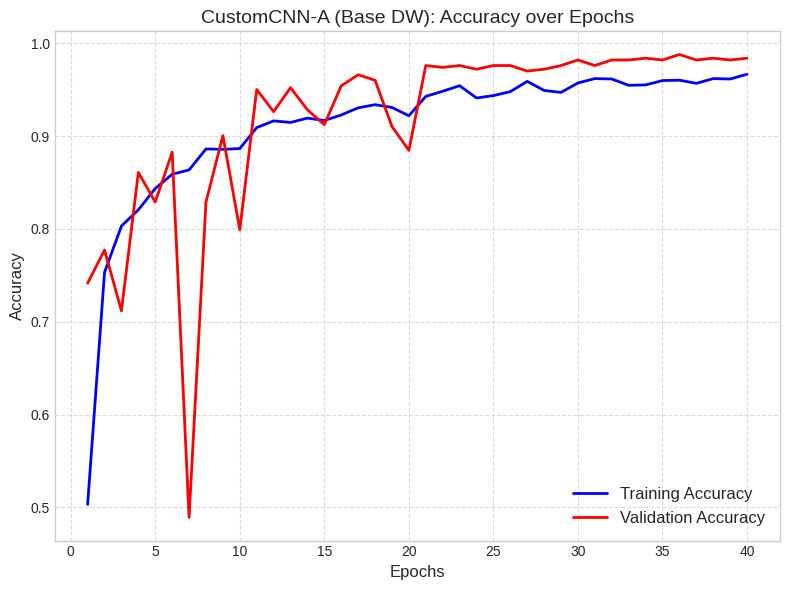

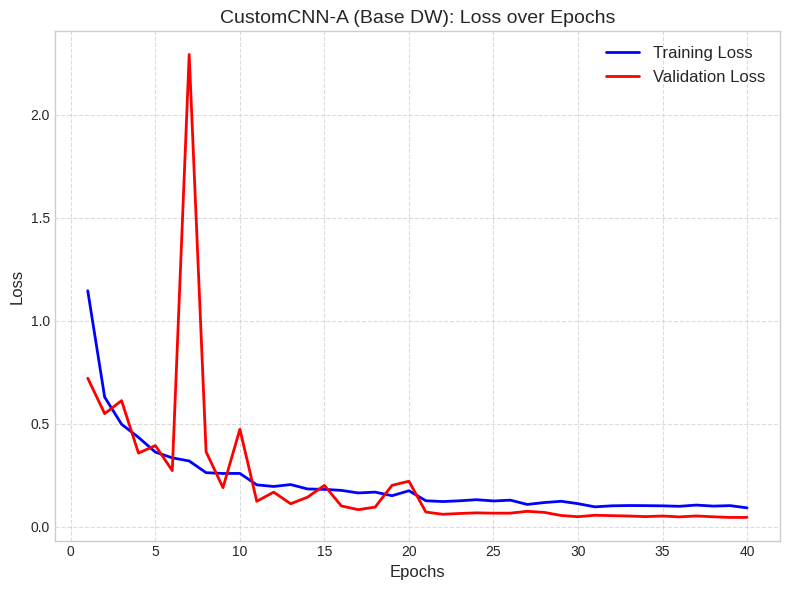


Training CustomCNN-B (DW + SE)
Training on device: cuda

Epoch 1/40
---------------


/tmp/ipykernel_22/4030074278.py:64: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Train Loss: 1.2699 | Acc: 0.5194 | Macro-F1: 0.4926


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Val Loss: 0.8871 | Acc: 0.5865 | Macro-F1: 0.5724
  --> Best model updated!

Epoch 2/40
---------------


...

Val Loss: 0.0777 | Acc: 0.9702 | Macro-F1: 0.9767

Epoch 18/40
---------------


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Train Loss: 0.1194 | Acc: 0.9476 | Macro-F1: 0.9565


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Val Loss: 0.0635 | Acc: 0.9682 | Macro-F1: 0.9735

Early stopping triggered after 18 epochs.

Training complete. Best Val Macro-F1: 0.9786


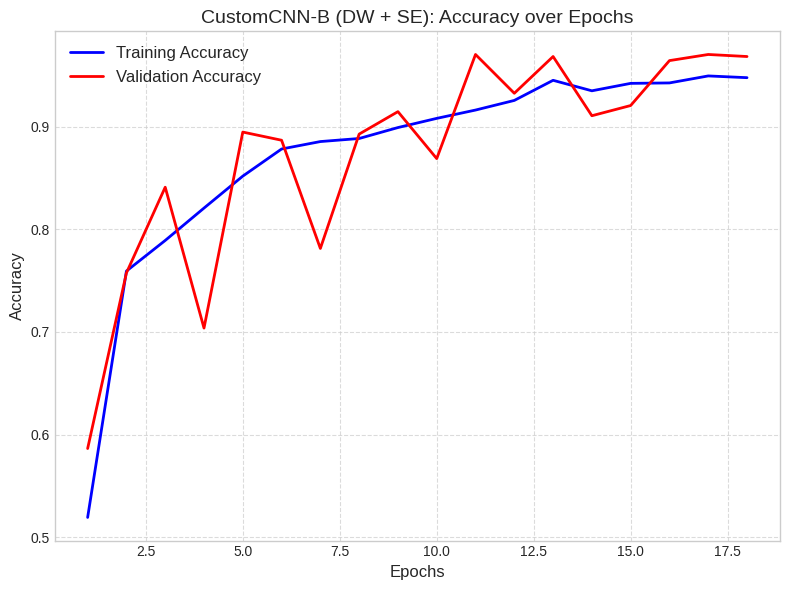

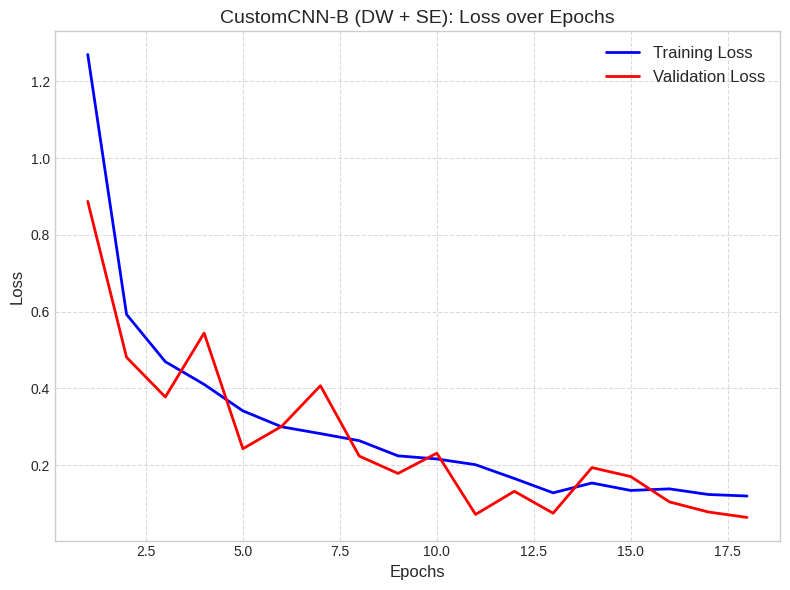


Training CustomCNN-C (DW + Res)
Training on device: cuda

Epoch 1/40
---------------


/tmp/ipykernel_22/4030074278.py:64: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Train Loss: 1.0663 | Acc: 0.5373 | Macro-F1: 0.5632


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Val Loss: 0.6911 | Acc: 0.6978 | Macro-F1: 0.7292
  --> Best model updated!

Epoch 2/40
---------------


...

Val Loss: 0.1628 | Acc: 0.9165 | Macro-F1: 0.9307

Epoch 28/40
---------------


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Train Loss: 0.1242 | Acc: 0.9540 | Macro-F1: 0.9613


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Val Loss: 0.0638 | Acc: 0.9881 | Macro-F1: 0.9898

Early stopping triggered after 28 epochs.

Training complete. Best Val Macro-F1: 0.9901


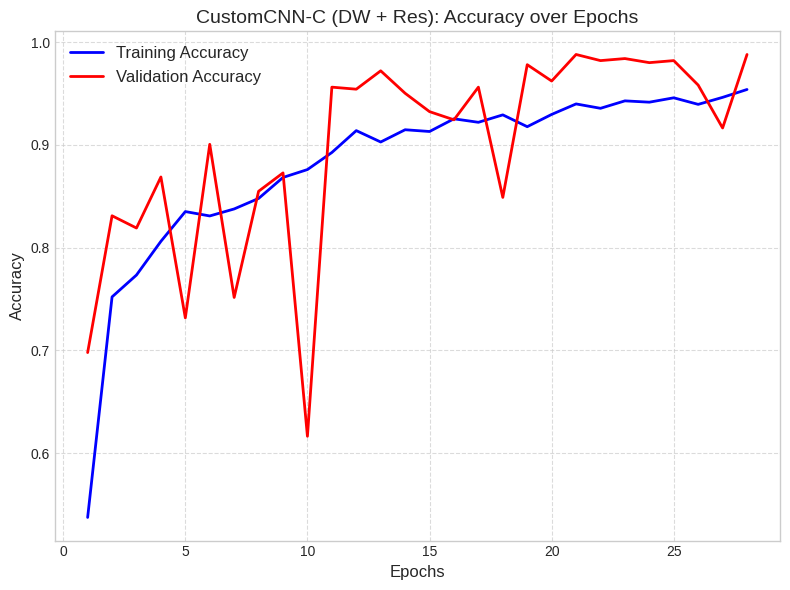

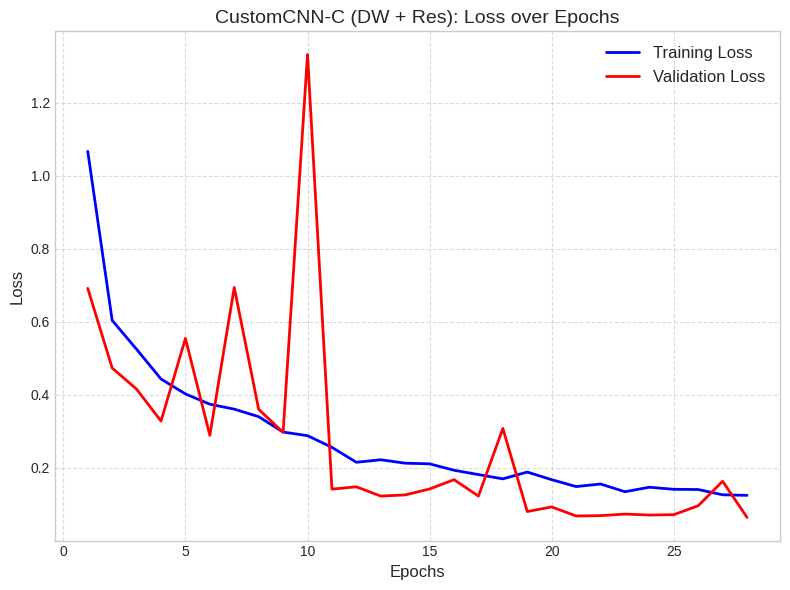


-----------------------------------------------------------------
TABLE F: ABLATION STUDY RESULTS
-----------------------------------------------------------------
                 Model DW Conv SE Attention Residual  Parameters  GFLOPs  Test_Macro_F1  Latency_ms
 CustomCNN-A (Base DW)     Yes           No       No       37798  0.1581         0.9913        1.43
 CustomCNN-B (DW + SE)     Yes          Yes       No       58790  0.1601         0.9794        2.41
CustomCNN-C (DW + Res)     Yes           No      Yes       37798  0.1581         0.9888        1.31
CustomCNN-D (Proposed)     Yes          Yes      Yes       58790  0.1601         0.9953        2.34

Saved Ablation table to /kaggle/working/table_f_ablation_study.csv


In [14]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import os
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from thop import profile
import gc

print("--- Phase 23: Executing Ablation Study ---")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Define the ablation variants
ablation_configs = {
    "CustomCNN-A (Base DW)": {"use_se": False, "use_residual": False},
    "CustomCNN-B (DW + SE)": {"use_se": True, "use_residual": False},
    "CustomCNN-C (DW + Res)": {"use_se": False, "use_residual": True}
}

ablation_results = []

for name, config in ablation_configs.items():
    print(f"\n{'='*50}\nTraining {name}\n{'='*50}")
    
    # 1. Initialize Variant
    model = CustomLightweightCNN(num_classes=6, use_se=config["use_se"], use_residual=config["use_residual"])
    model = model.to(device)
    
    # 2. Setup Training (Identical config)
    criterion = nn.CrossEntropyLoss(weight=weights) # assuming 'weights' from Phase 3 is in memory
    optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)
    
    # 3. Train Variant
    best_model, history = train_model(
        model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=40, patience=7
    )
    
    # Save and Plot
    safe_name = name.lower().replace(" ", "_").replace("(", "").replace(")", "").replace("+", "and")
    model_path = f'/kaggle/working/{safe_name}_weights.pth'
    torch.save(best_model.state_dict(), model_path)
    plot_and_show_curves(history, model_name=name)
    
    # 4. Computational Efficiency
    model.eval()
    total_params = sum(p.numel() for p in model.parameters())
    model_size_mb = os.path.getsize(model_path) / (1024 * 1024)
    
    dummy_input = torch.randn(1, 3, 224, 224).to(device)
    macs, _ = profile(model, inputs=(dummy_input,), verbose=False)
    flops_giga = (macs * 2) / 1e9
    
    # Latency
    for _ in range(50): _ = model(dummy_input)
    start_events = [torch.cuda.Event(enable_timing=True) for _ in range(100)]
    end_events = [torch.cuda.Event(enable_timing=True) for _ in range(100)]
    
    with torch.no_grad():
        for i in range(100):
            start_events[i].record()
            _ = model(dummy_input)
            end_events[i].record()
            
    torch.cuda.synchronize()
    times = [s.elapsed_time(e) for s, e in zip(start_events, end_events)]
    mean_latency = np.mean(times)
    
    # 5. Test Set Evaluation
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            with torch.amp.autocast('cuda'):
                outputs = model(inputs)
                _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            
    test_acc = accuracy_score(all_labels, all_preds)
    _, _, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro', zero_division=0)
    
    # 6. Store Result
    ablation_results.append({
        "Model": name,
        "DW Conv": "Yes",
        "SE Attention": "Yes" if config["use_se"] else "No",
        "Residual": "Yes" if config["use_residual"] else "No",
        "Parameters": total_params,
        "GFLOPs": round(flops_giga, 4),
        "Test_Macro_F1": round(f1, 4),
        "Latency_ms": round(mean_latency, 2)
    })
    
    # Cleanup
    del model, best_model, optimizer
    torch.cuda.empty_cache()
    gc.collect()

# 7. Generate Final Table F (Ablation Study)
# We pull CustomCNN-D from the main CSV to complete the table
main_csv_path = '/kaggle/working/baseline_COMPUTATIONAL_EFFICIENCY.csv'
main_df = pd.read_csv(main_csv_path)
custom_d_row = main_df[main_df['Model'] == 'CustomCNN-D'].iloc[0]

ablation_results.append({
    "Model": "CustomCNN-D (Proposed)",
    "DW Conv": "Yes",
    "SE Attention": "Yes",
    "Residual": "Yes",
    "Parameters": custom_d_row['Parameters'],
    "GFLOPs": custom_d_row['GFLOPs'],
    "Test_Macro_F1": custom_d_row['Test_Macro_F1'],
    "Latency_ms": custom_d_row['Latency_ms']
})

ablation_df = pd.DataFrame(ablation_results)
ablation_csv_path = '/kaggle/working/table_f_ablation_study.csv'
ablation_df.to_csv(ablation_csv_path, index=False)

print("\n" + "-" * 65)
print("TABLE F: ABLATION STUDY RESULTS")
print("-" * 65)
print(ablation_df.to_string(index=False))
print(f"\nSaved Ablation table to {ablation_csv_path}")

In [15]:
# ============================================================
# PHASE 24: STATISTICAL RELIABILITY (MULTI-SEED RUNS)
# ============================================================

import os
import gc
import random
import hashlib

import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support


print("--- Phase 24: Statistical Reliability (Multi-Seed Runs) ---")

# ------------------------------------------------------------
# 1. Device
# ------------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")


# ------------------------------------------------------------
# 2. Random Seed Function
# ------------------------------------------------------------
def set_all_seeds(seed):
    """
    Set all relevant random seeds so that each experiment
    is reproducible as far as practically possible.
    """
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Improve reproducibility on CUDA
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# ------------------------------------------------------------
# 3. Exact Duplicate Detection
# ------------------------------------------------------------
def calculate_file_hash(filepath):
    """
    Calculate SHA-256 hash of an image file.
    Identical files will have identical hashes.
    """
    sha256 = hashlib.sha256()

    with open(filepath, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


# ------------------------------------------------------------
# 4. Build Clean Dataset
# ------------------------------------------------------------
def build_clean_dataframe():
    """
    Collect all dataset images and remove exact duplicates
    before any train/validation/test split.

    This makes the multi-seed experiments consistent with
    the main experiment.
    """

    data = []

    duplicate_count = 0
    seen_hashes = set()

    valid_extensions = (".png", ".jpg", ".jpeg")

    # Sort classes and filenames for deterministic processing
    for cls in sorted(EXPECTED_CLASSES):

        cls_dir = os.path.join(DATA_DIR, cls)

        if not os.path.exists(cls_dir):
            print(f"WARNING: Class directory not found: {cls_dir}")
            continue

        images = sorted([
            f for f in os.listdir(cls_dir)
            if f.lower().endswith(valid_extensions)
        ])

        for img_name in images:

            full_path = os.path.join(cls_dir, img_name)

            # Safety check
            if not os.path.isfile(full_path):
                continue

            # Exact duplicate detection
            img_hash = calculate_file_hash(full_path)

            if img_hash in seen_hashes:
                duplicate_count += 1
                continue

            seen_hashes.add(img_hash)

            data.append({
                "filepath": os.path.join(cls, img_name),
                "class": cls
            })

    df = pd.DataFrame(data)

    print("\nDataset integrity:")
    print(f"Original unique image records collected: {len(df) + duplicate_count}")
    print(f"Exact duplicates removed: {duplicate_count}")
    print(f"Final unique images: {len(df)}")

    print("\nClass distribution after duplicate removal:")
    print(df["class"].value_counts().sort_index())

    return df


# ------------------------------------------------------------
# 5. Create Independent Stratified Split for Each Seed
# ------------------------------------------------------------
def create_split_for_seed(df, seed):
    """
    Create a new 70/15/15 stratified train/validation/test
    split from the SAME duplicate-free dataset.
    """

    # --------------------------------------------------------
    # 70% Train / 30% Temporary
    # --------------------------------------------------------
    train_df, temp_df = train_test_split(
        df,
        test_size=0.30,
        random_state=seed,
        stratify=df["class"]
    )

    # --------------------------------------------------------
    # 15% Validation / 15% Test
    # --------------------------------------------------------
    val_df, test_df = train_test_split(
        temp_df,
        test_size=0.50,
        random_state=seed,
        stratify=temp_df["class"]
    )

    # Avoid SettingWithCopyWarning
    train_df = train_df.copy()
    val_df = val_df.copy()
    test_df = test_df.copy()

    train_df["split"] = "train"
    val_df["split"] = "val"
    test_df["split"] = "test"

    final_df = pd.concat(
        [train_df, val_df, test_df],
        ignore_index=True
    )

    csv_path = f"/kaggle/working/dataset_split_seed_{seed}.csv"
    final_df.to_csv(csv_path, index=False)

    # --------------------------------------------------------
    # Verification
    # --------------------------------------------------------
    print(f"\nSeed {seed} split:")
    print(f"Train: {len(train_df)}")
    print(f"Validation: {len(val_df)}")
    print(f"Test: {len(test_df)}")
    print(f"Total: {len(final_df)}")

    print("\nClass distribution:")
    print(
        final_df.groupby(["split", "class"])
        .size()
        .unstack(fill_value=0)
    )

    # --------------------------------------------------------
    # Check for overlap between splits
    # --------------------------------------------------------
    train_paths = set(train_df["filepath"])
    val_paths = set(val_df["filepath"])
    test_paths = set(test_df["filepath"])

    train_val_overlap = train_paths.intersection(val_paths)
    train_test_overlap = train_paths.intersection(test_paths)
    val_test_overlap = val_paths.intersection(test_paths)

    print("\nSplit overlap verification:")
    print(f"Train ∩ Validation: {len(train_val_overlap)}")
    print(f"Train ∩ Test:       {len(train_test_overlap)}")
    print(f"Validation ∩ Test:  {len(val_test_overlap)}")

    assert len(train_val_overlap) == 0
    assert len(train_test_overlap) == 0
    assert len(val_test_overlap) == 0

    return csv_path


# ------------------------------------------------------------
# 6. Prepare One Duplicate-Free Master Dataset
# ------------------------------------------------------------
MASTER_DF = build_clean_dataframe()


# ------------------------------------------------------------
# 7. Multi-Seed Experiments
# ------------------------------------------------------------
SEEDS = [10, 100, 777]

detailed_results = []


for seed in SEEDS:

    print("\n" + "=" * 70)
    print(f"RUNNING INDEPENDENT SEED: {seed}")
    print("=" * 70)

    # --------------------------------------------------------
    # Set ALL random seeds before anything stochastic happens
    # --------------------------------------------------------
    set_all_seeds(seed)

    # --------------------------------------------------------
    # Create new stratified split
    # --------------------------------------------------------
    seed_csv = create_split_for_seed(
        MASTER_DF,
        seed
    )

    # --------------------------------------------------------
    # Initialize datasets
    # --------------------------------------------------------
    seed_train_dataset = GuavaLeafDataset(
        csv_file=seed_csv,
        root_dir=DATA_DIR,
        split="train",
        transform=train_transform
    )

    seed_val_dataset = GuavaLeafDataset(
        csv_file=seed_csv,
        root_dir=DATA_DIR,
        split="val",
        transform=val_test_transform
    )

    seed_test_dataset = GuavaLeafDataset(
        csv_file=seed_csv,
        root_dir=DATA_DIR,
        split="test",
        transform=val_test_transform
    )

    # --------------------------------------------------------
    # DataLoaders
    # --------------------------------------------------------

    # Generator controls DataLoader shuffling reproducibly
    train_generator = torch.Generator()
    train_generator.manual_seed(seed)

    seed_train_loader = torch.utils.data.DataLoader(
        seed_train_dataset,
        batch_size=32,
        shuffle=True,
        generator=train_generator
    )

    seed_val_loader = torch.utils.data.DataLoader(
        seed_val_dataset,
        batch_size=32,
        shuffle=False
    )

    seed_test_loader = torch.utils.data.DataLoader(
        seed_test_dataset,
        batch_size=32,
        shuffle=False
    )

    # --------------------------------------------------------
    # Class Weights
    # --------------------------------------------------------
    class_counts = (
        seed_train_dataset.dataframe["class"]
        .value_counts()
        .sort_index()
        .values
    )

    seed_weights = torch.tensor(
        len(seed_train_dataset) /
        (len(EXPECTED_CLASSES) * class_counts),
        dtype=torch.float32
    ).to(device)

    print("\nTraining class counts:")
    print(class_counts)

    print("\nClass weights:")
    print(seed_weights.detach().cpu().numpy())

    criterion = nn.CrossEntropyLoss(
        weight=seed_weights
    )

    # --------------------------------------------------------
    # Initialize CustomCNN-D
    # --------------------------------------------------------
    # Important:
    # The seed is already fixed BEFORE model initialization.
    # Therefore, model weights are different and reproducible
    # for each seed.
    # --------------------------------------------------------
    model = CustomLightweightCNN(
        num_classes=6,
        use_se=True,
        use_residual=True
    ).to(device)

    # --------------------------------------------------------
    # Optimizer
    # --------------------------------------------------------
    optimizer = optim.AdamW(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-4
    )

    # --------------------------------------------------------
    # Learning-rate scheduler
    # --------------------------------------------------------
    scheduler = optim.lr_scheduler.StepLR(
        optimizer,
        step_size=10,
        gamma=0.5
    )

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------
    best_model, _ = train_model(
        model,
        seed_train_loader,
        seed_val_loader,
        criterion,
        optimizer,
        scheduler,
        num_epochs=40,
        patience=5
    )

    # --------------------------------------------------------
    # Evaluate on independent test set
    # --------------------------------------------------------
    best_model.eval()

    all_preds = []
    all_labels = []

    autocast_enabled = (device.type == "cuda")

    with torch.no_grad():

        for inputs, labels in seed_test_loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            with torch.amp.autocast(
                device_type=device.type,
                enabled=autocast_enabled
            ):
                outputs = best_model(inputs)

            preds = torch.argmax(outputs, dim=1)

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------
    acc = accuracy_score(
        all_labels,
        all_preds
    )

    precision, recall, f1, _ = precision_recall_fscore_support(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    print(
        f"\n--> Seed {seed} Results:"
    )
    print(
        f"    Test Accuracy : {acc * 100:.4f}%"
    )
    print(
        f"    Test Macro-F1 : {f1 * 100:.4f}%"
    )
    print(
        f"    Test Precision: {precision * 100:.4f}%"
    )
    print(
        f"    Test Recall   : {recall * 100:.4f}%"
    )

    # --------------------------------------------------------
    # Save RAW values
    # Do NOT round before calculating final mean/std.
    # --------------------------------------------------------
    detailed_results.append({
        "Seed": seed,
        "Test_Accuracy": acc,
        "Test_Macro_F1": f1,
        "Test_Precision": precision,
        "Test_Recall": recall
    })

    # --------------------------------------------------------
    # Cleanup
    # --------------------------------------------------------
    del model
    del best_model
    del optimizer
    del scheduler

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    gc.collect()


# ============================================================
# 8. Statistical Summary
# ============================================================

df_stats_raw = pd.DataFrame(detailed_results)

# ------------------------------------------------------------
# Mean and sample standard deviation
# ------------------------------------------------------------
mean_acc = df_stats_raw["Test_Accuracy"].mean() * 100
std_acc = df_stats_raw["Test_Accuracy"].std(ddof=1) * 100

mean_f1 = df_stats_raw["Test_Macro_F1"].mean() * 100
std_f1 = df_stats_raw["Test_Macro_F1"].std(ddof=1) * 100

mean_precision = df_stats_raw["Test_Precision"].mean() * 100
std_precision = df_stats_raw["Test_Precision"].std(ddof=1) * 100

mean_recall = df_stats_raw["Test_Recall"].mean() * 100
std_recall = df_stats_raw["Test_Recall"].std(ddof=1) * 100


# ============================================================
# 9. Create Publication-Friendly Table
# ============================================================

publication_results = []

for _, row in df_stats_raw.iterrows():

    publication_results.append({
        "Seed": str(row["Seed"]),
        "Test Accuracy (%)": f"{row['Test_Accuracy'] * 100:.2f}",
        "Test Macro-F1 (%)": f"{row['Test_Macro_F1'] * 100:.2f}",
        "Test Precision (%)": f"{row['Test_Precision'] * 100:.2f}",
        "Test Recall (%)": f"{row['Test_Recall'] * 100:.2f}"
    })


publication_results.append({
    "Seed": "Mean ± SD",
    "Test Accuracy (%)": f"{mean_acc:.2f} ± {std_acc:.2f}",
    "Test Macro-F1 (%)": f"{mean_f1:.2f} ± {std_f1:.2f}",
    "Test Precision (%)": f"{mean_precision:.2f} ± {std_precision:.2f}",
    "Test Recall (%)": f"{mean_recall:.2f} ± {std_recall:.2f}"
})


df_stats = pd.DataFrame(publication_results)


# ============================================================
# 10. Save Results
# ============================================================

csv_path = (
    "/kaggle/working/"
    "table_h_statistical_reliability.csv"
)

df_stats.to_csv(
    csv_path,
    index=False
)


# ============================================================
# 11. Display Final Results
# ============================================================

print("\n" + "-" * 70)
print("STATISTICAL RELIABILITY RESULT (TABLE H)")
print("-" * 70)

print(
    df_stats.to_string(index=False)
)

print("\n" + "-" * 70)
print("STATISTICAL SUMMARY")
print("-" * 70)

print(
    f"Accuracy     : {mean_acc:.2f} ± {std_acc:.2f}%"
)

print(
    f"Macro-F1     : {mean_f1:.2f} ± {std_f1:.2f}%"
)

print(
    f"Precision    : {mean_precision:.2f} ± {std_precision:.2f}%"
)

print(
    f"Recall       : {mean_recall:.2f} ± {std_recall:.2f}%"
)

print("\nSaved statistical data to:")
print(csv_path)

--- Phase 24: Statistical Reliability (Multi-Seed Runs) ---
Device: cuda

Dataset integrity:
Original unique image records collected: 3355
Exact duplicates removed: 1
Final unique images: 3354

Class distribution after duplicate removal:
class
Anthracnose           773
Dried                 271
Healthy               831
Insect_Infestation    441
Senescence            510
Sooty_Mould           528
Name: count, dtype: int64

RUNNING INDEPENDENT SEED: 10

Seed 10 split:
Train: 2347
Validation: 503
Test: 504
Total: 3354

Class distribution:
class  Anthracnose  Dried  Healthy  Insect_Infestation  Senescence  \
split                                                                
test           116     40      125                  66          77   
train          541    190      581                 309         357   
val            116     41      125                  66          76   

class  Sooty_Mould  
split               
test            80  
train          369  
val             79  



/tmp/ipykernel_22/4030074278.py:64: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Train Loss: 1.2309 | Acc: 0.4580 | Macro-F1: 0.4827


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Val Loss: 0.7420 | Acc: 0.6779 | Macro-F1: 0.7163
  --> Best model updated!

Epoch 2/40
---------------


...

Val Loss: 0.0459 | Acc: 0.9801 | Macro-F1: 0.9842

Epoch 39/40
---------------


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Train Loss: 0.0674 | Acc: 0.9706 | Macro-F1: 0.9753


/tmp/ipykernel_22/4030074278.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Val Loss: 0.0225 | Acc: 0.9920 | Macro-F1: 0.9935

Early stopping triggered after 39 epochs.

Training complete. Best Val Macro-F1: 1.0000

--> Seed 777 Results:
    Test Accuracy : 99.0079%
    Test Macro-F1 : 99.1662%
    Test Precision: 99.1276%
    Test Recall   : 99.2170%

----------------------------------------------------------------------
STATISTICAL RELIABILITY RESULT (TABLE H)
----------------------------------------------------------------------
     Seed Test Accuracy (%) Test Macro-F1 (%) Test Precision (%) Test Recall (%)
     10.0             98.81             99.06              98.98           99.15
    100.0             96.43             97.28              97.10           97.49
    777.0             99.01             99.17              99.13           99.22
Mean ± SD      98.08 ± 1.44      98.50 ± 1.06       98.41 ± 1.13    98.62 ± 0.98

----------------------------------------------------------------------
STATISTICAL SUMMARY
-----------------------------------------

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
--- Phase 25 & 26: Comprehensive Class-by-Class Grad-CAM ---


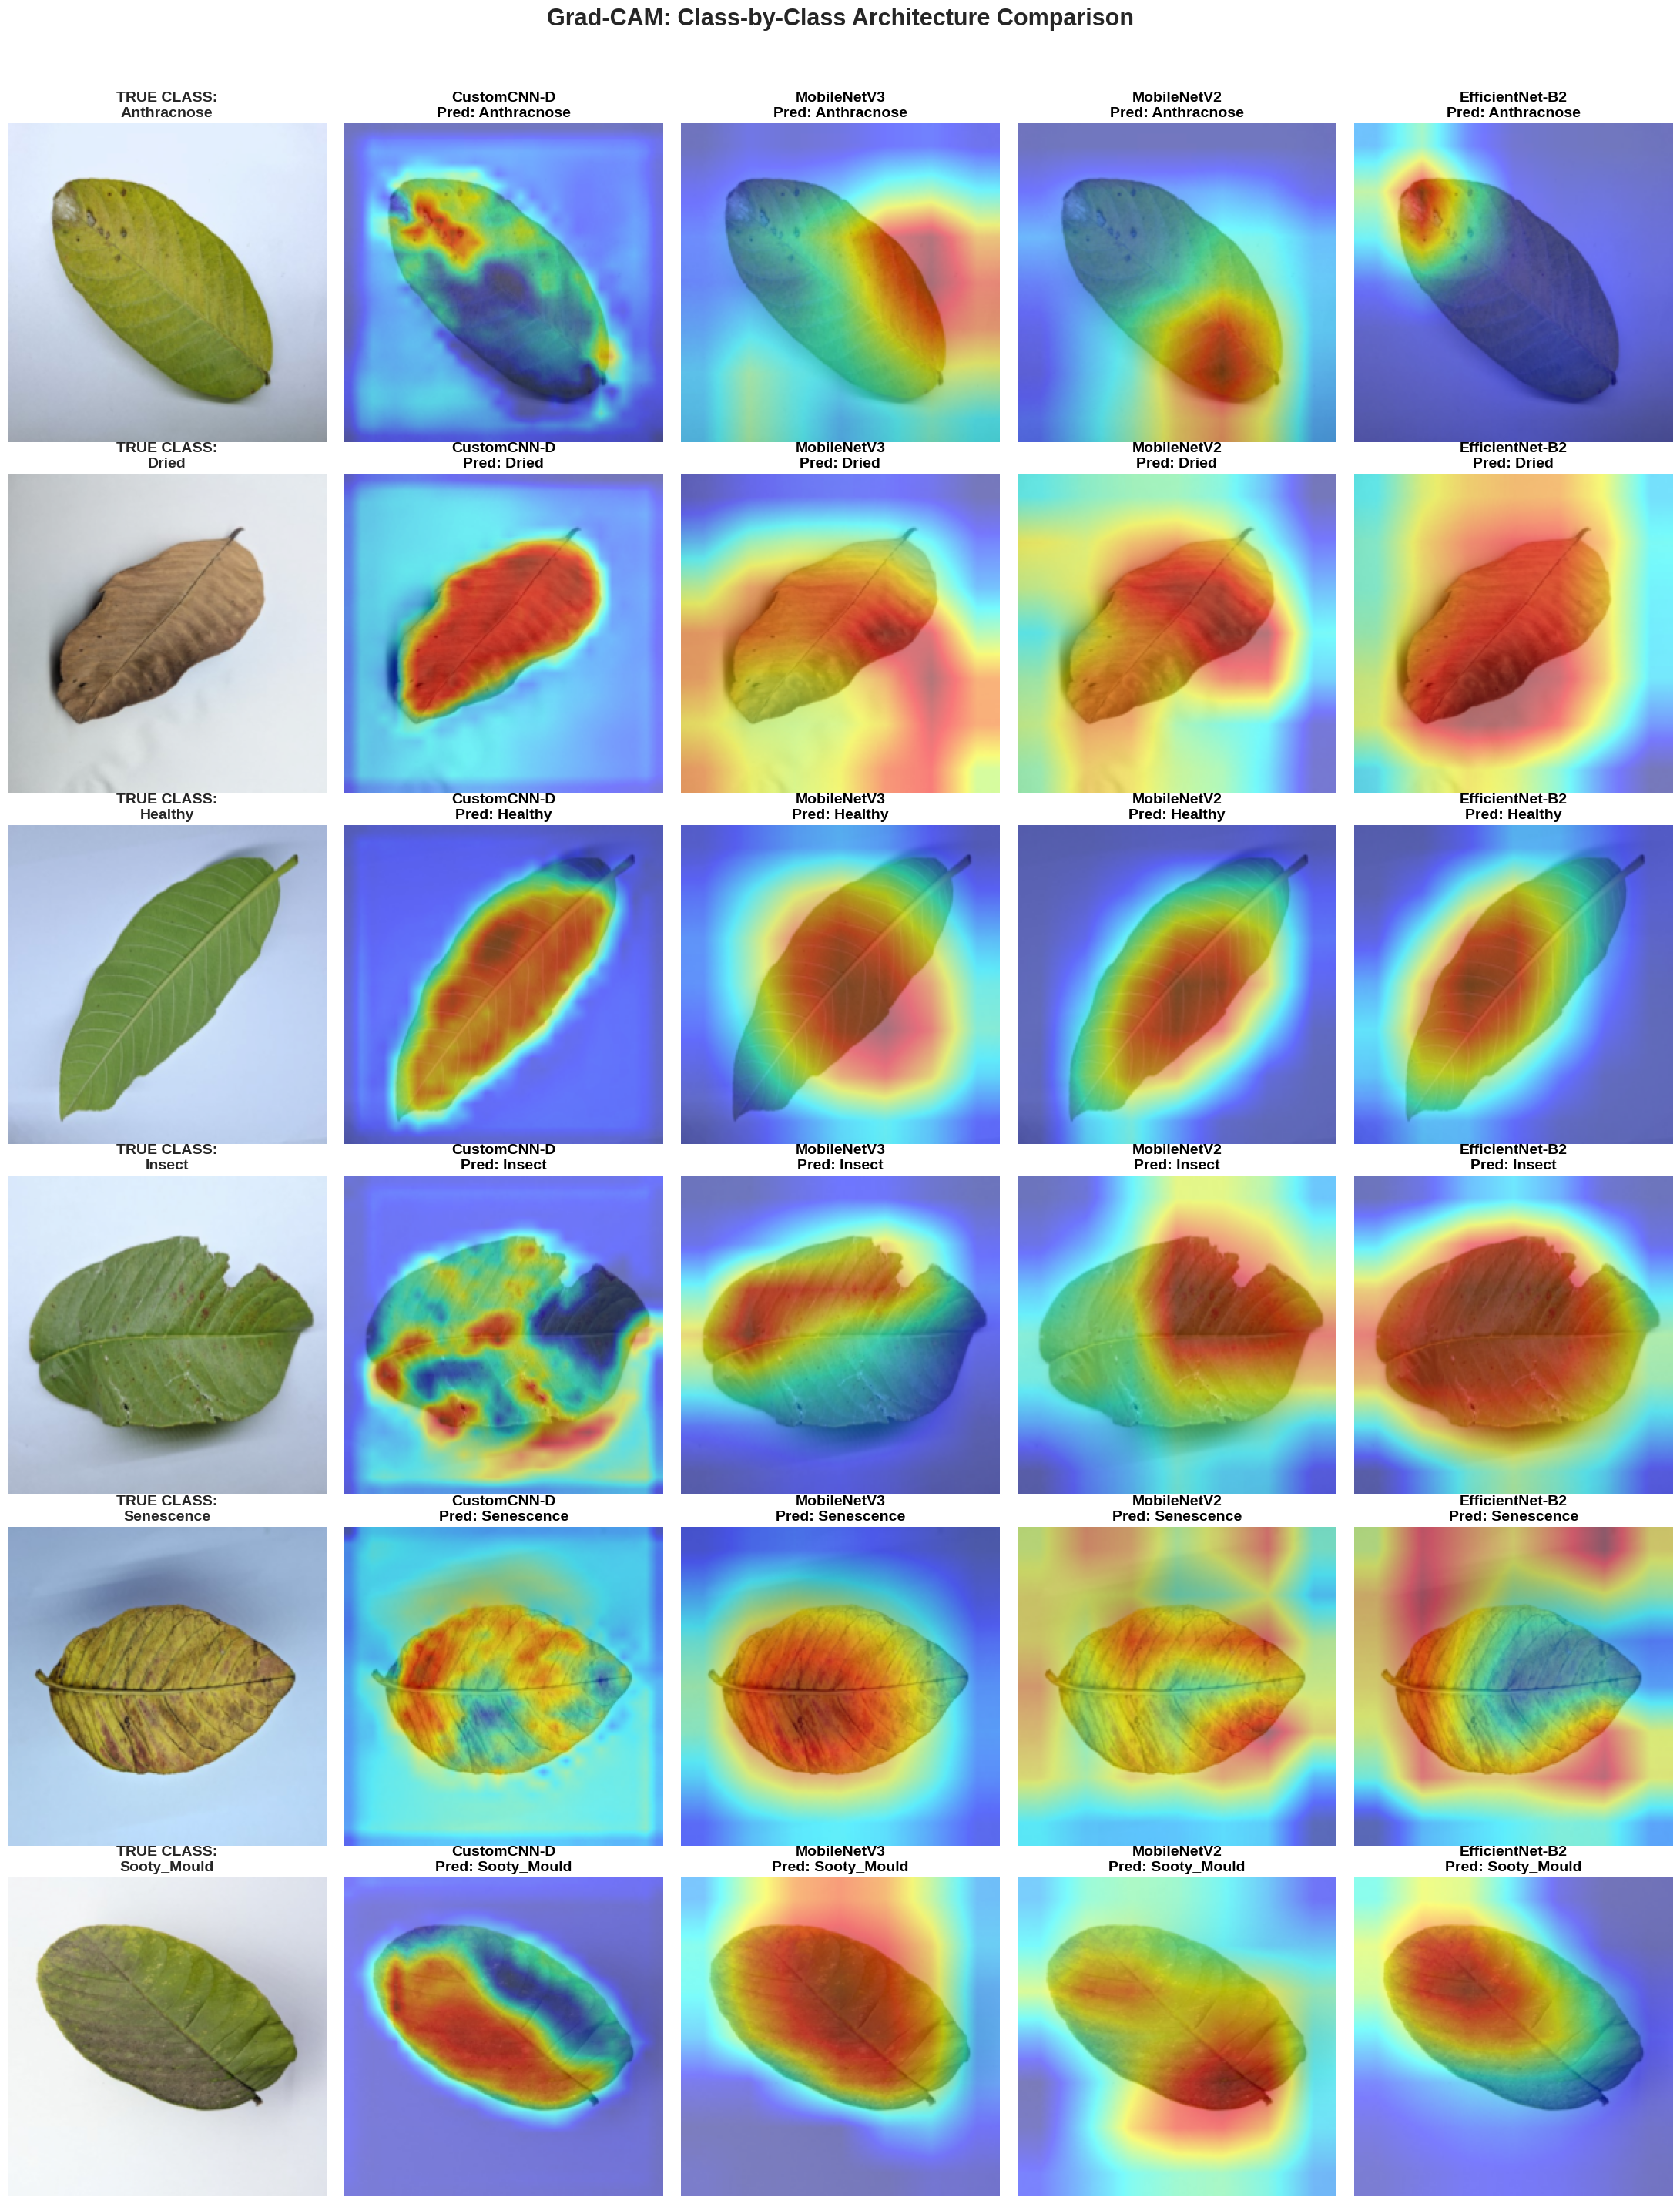

Saved class-by-class Grad-CAM visualizations to /kaggle/working/figure5_class_by_class_gradcam.png


In [16]:
!pip install grad-cam --quiet

import torch
import torch.nn as nn
import torchvision.models as models
import numpy as np
import matplotlib.pyplot as plt
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

print("--- Phase 25 & 26: Comprehensive Class-by-Class Grad-CAM ---")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class_names = ['Anthracnose', 'Dried', 'Healthy', 'Insect', 'Senescence', 'Sooty_Mould']

# ---------------------------------------------------------
# 1. Load All 4 Models
# ---------------------------------------------------------
custom_model = CustomLightweightCNN(num_classes=6, use_se=True, use_residual=True)
custom_model.load_state_dict(torch.load('/kaggle/working/custom_cnn_d_weights.pth'))
custom_model.to(device).eval()

mbv3 = models.mobilenet_v3_small(weights=None)
mbv3.classifier[3] = nn.Linear(mbv3.classifier[3].in_features, 6)
mbv3.load_state_dict(torch.load('/kaggle/working/mobilenetv3_small_weights.pth'))
mbv3.to(device).eval()

mbv2 = models.mobilenet_v2(weights=None)
mbv2.classifier[1] = nn.Linear(mbv2.classifier[1].in_features, 6)
mbv2.load_state_dict(torch.load('/kaggle/working/mobilenetv2_scratch_weights.pth'))
mbv2.to(device).eval()

eff_b2 = models.efficientnet_b2(weights=None)
eff_b2.classifier[1] = nn.Linear(eff_b2.classifier[1].in_features, 6)
eff_b2.load_state_dict(torch.load('/kaggle/working/efficientnet_b2_scratch_weights.pth'))
eff_b2.to(device).eval()

model_dict = {
    "CustomCNN-D": (custom_model, [custom_model.block3_2]),
    "MobileNetV3": (mbv3, [mbv3.features[-1]]),
    "MobileNetV2": (mbv2, [mbv2.features[-1]]),
    "EfficientNet-B2": (eff_b2, [eff_b2.features[-1]])
}

# ---------------------------------------------------------
# 2. Extract exactly ONE image per class from the test set
# ---------------------------------------------------------
representative_images = {} # dict mapping class_idx -> image_tensor

for inputs, labels in test_loader:
    for i in range(inputs.size(0)):
        lbl = labels[i].item()
        if lbl not in representative_images:
            representative_images[lbl] = inputs[i]
        if len(representative_images) == 6:
            break
    if len(representative_images) == 6:
        break

# ---------------------------------------------------------
# 3. Generate Visualizations (6 rows x 5 columns)
# ---------------------------------------------------------
num_cols = len(model_dict) + 1 # 1 for original image + 4 models
num_rows = 6 # One for each class

fig, axs = plt.subplots(num_rows, num_cols, figsize=(22, 28))
fig.suptitle('Grad-CAM: Class-by-Class Architecture Comparison', fontsize=22, fontweight='bold', y=1.02)

# Sort by class index to ensure consistent row order (Anthracnose -> Sooty Mould)
for row_idx, class_idx in enumerate(sorted(representative_images.keys())):
    img_tensor = representative_images[class_idx]
    input_tensor = img_tensor.unsqueeze(0).to(device)
    true_label = class_idx
    targets = [ClassifierOutputTarget(true_label)]
    
    # Un-normalize original image for plotting
    img_np = img_tensor.cpu().numpy().transpose(1, 2, 0)
    mean, std = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])
    img_unnorm = np.clip(std * img_np + mean, 0, 1)
    
    # Plot Original Image
    axs[row_idx, 0].imshow(img_unnorm)
    axs[row_idx, 0].set_title(f'TRUE CLASS:\n{class_names[true_label]}', fontsize=14, fontweight='bold')
    axs[row_idx, 0].axis('off')
    
    # Generate and plot CAM for each model
    col_idx = 1
    for name, (model, target_layer) in model_dict.items():
        # A. Get the Prediction
        with torch.no_grad():
            outputs = model(input_tensor)
            pred_idx = torch.argmax(outputs, dim=1).item()
            pred_name = class_names[pred_idx]
            
        # Determine title color (Red if wrong, Black if correct)
        title_color = 'red' if pred_idx != true_label else 'black'
        
        # B. Get the Grad-CAM
        cam = GradCAM(model=model, target_layers=target_layer)
        grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
        visualization = show_cam_on_image(img_unnorm, grayscale_cam, use_rgb=True)
        
        # C. Plot
        axs[row_idx, col_idx].imshow(visualization)
        axs[row_idx, col_idx].set_title(f'{name}\nPred: {pred_name}', fontsize=14, color=title_color, fontweight='bold')
        axs[row_idx, col_idx].axis('off')
        col_idx += 1

plt.tight_layout()
output_path = '/kaggle/working/figure5_class_by_class_gradcam.png'
plt.savefig(output_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Saved class-by-class Grad-CAM visualizations to {output_path}")

--- Phase 28: Error Analysis for CustomCNN-D ---

Total Test Samples: 504
Total Correct:      501
Total Errors:       3

MISCLASSIFICATION SUMMARY (CustomCNN-D)
 Test_Sample_Index  True_Label Predicted_Label
               130      Insect         Healthy
               148 Anthracnose         Healthy
               183 Anthracnose         Healthy

Saved error analysis log to: /kaggle/working/table_i_error_analysis.csv


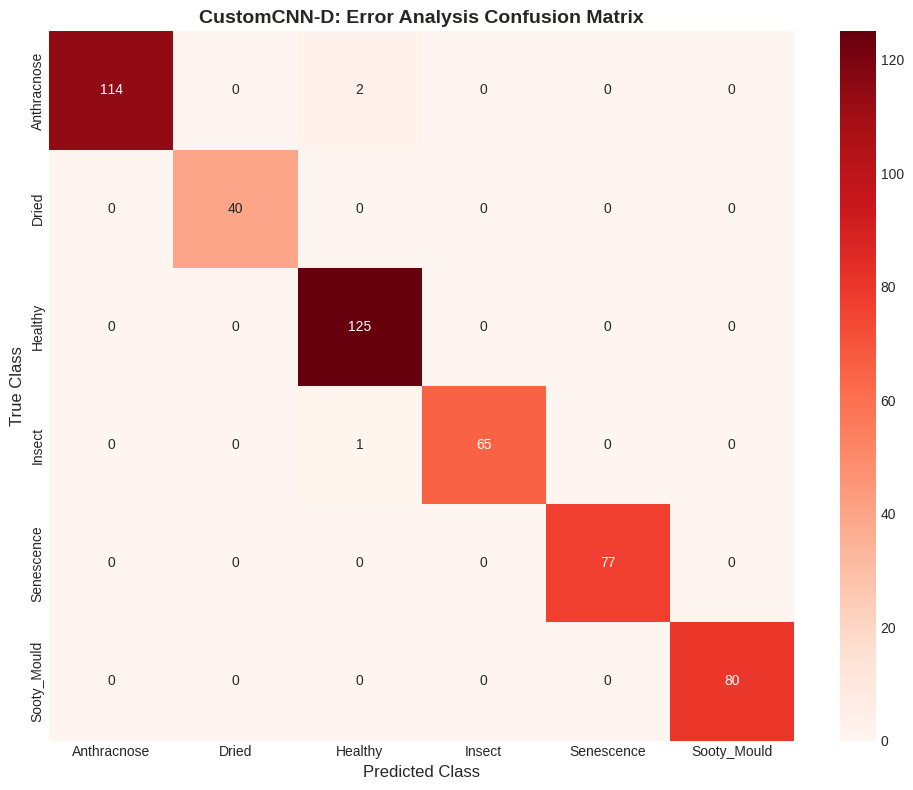

In [17]:
import torch
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print("--- Phase 28: Error Analysis for CustomCNN-D ---")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class_names = ['Anthracnose', 'Dried', 'Healthy', 'Insect', 'Senescence', 'Sooty_Mould']

# 1. Ensure CustomCNN-D is loaded and in evaluation mode
custom_model = CustomLightweightCNN(num_classes=6, use_se=True, use_residual=True)
custom_model.load_state_dict(torch.load('/kaggle/working/custom_cnn_d_weights.pth'))
custom_model.to(device)
custom_model.eval()

# 2. Collect all predictions, true labels, and corresponding image identifiers if possible
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)
        
        with torch.amp.autocast('cuda'):
            outputs = custom_model(inputs)
            _, preds = torch.max(outputs, 1)
            
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# 3. Find Misclassifications
incorrect_indices = np.where(all_preds != all_labels)[0]

print(f"\nTotal Test Samples: {len(all_labels)}")
print(f"Total Correct:      {len(all_labels) - len(incorrect_indices)}")
print(f"Total Errors:       {len(incorrect_indices)}")

# 4. Build a Detailed Error Log DataFrame
error_data = []
for idx in incorrect_indices:
    true_cls = class_names[all_labels[idx]]
    pred_cls = class_names[all_preds[idx]]
    error_data.append({
        "Test_Sample_Index": idx,
        "True_Label": true_cls,
        "Predicted_Label": pred_cls
    })

error_df = pd.DataFrame(error_data)

if not error_df.empty:
    print("\n" + "=" * 50)
    print("MISCLASSIFICATION SUMMARY (CustomCNN-D)")
    print("=" * 50)
    print(error_df.to_string(index=False))
    
    # Save error log
    error_csv_path = '/kaggle/working/table_i_error_analysis.csv'
    error_df.to_csv(error_csv_path, index=False)
    print(f"\nSaved error analysis log to: {error_csv_path}")
else:
    print("\nIncredible! CustomCNN-D achieved 0 errors on this test split seed!")

# 5. Plot Detailed Confusion Matrix with Annotations
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=class_names, yticklabels=class_names)
plt.title('CustomCNN-D: Error Analysis Confusion Matrix', fontsize=14, fontweight='bold')
plt.ylabel('True Class', fontsize=12)
plt.xlabel('Predicted Class', fontsize=12)
plt.tight_layout()
plt.savefig('/kaggle/working/figure6_error_confusion_matrix.png', dpi=300)
plt.show()

In [18]:
import os
import subprocess
from IPython.display import FileLink

os.chdir('/kaggle/working/')
!zip -r research_backup_files.zip *.csv *.png *.pth > /dev/null 2>&1
FileLink('research_backup_files.zip')

/kaggle/working/research_backup_files.zip